# 기대 모델 피팅

`EDA.ipynb`(1부 전처리 · 2부 EDA)와 `build_mart.ipynb`(분석 테이블)의 다음 단계인 **기대 모델 피팅부터** 다룸.

- 설계 근거: `docs/설계 문서` 3절 (정한 것) · 연구계획서(비공개) 6.3·그림 1
- 분석 테이블: `docs/분석테이블_정리.docx`
- EDA 수치·그림: `docs/EDA_정리.docx`
- 커널: conda 환경 **impok** (Python 3.11)

예정 구성

| 절 | 내용 |
|---|---|
| 1 | 준비 — 라이브러리 |
| 2 | 분석 테이블 불러오기 (`data/mart.parquet`) |
| 3 | 기대 모델 — LightGBM + 이소토닉 보정 (정상 기간, 유저 단위 5조각) |
| 4 | 보정 확인 |
| 5 | 평가 기간 기대값 p · 편차(실제 − p) |
| 6 | 로지스틱 회귀 기준선 |


## 1. 준비

In [4]:
# 기대 모델 피팅에 쓰는 라이브러리임 (impok 환경에 모두 설치되어 있음)
import numpy as np                 # 숫자 배열 계산
import pandas as pd                # 표 다루기
import matplotlib.pyplot as plt    # 그래프

import sklearn
import lightgbm as lgb                                    # 기대 모델 주 모델 (계획서 6.3, 방법 A)
from sklearn.isotonic import IsotonicRegression           # 확률 보정 — 점수를 실제 재방문율로 맞춤
from sklearn.linear_model import LogisticRegression       # 비교 기준선 모델
from sklearn.model_selection import GroupKFold            # 유저 단위로 조각을 나눔 (같은 유저가 학습·보정에 같이 들어가지 않게)
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss   # 성능·보정 점검용

# 표 출력이 줄바꿈으로 깨지지 않게 넓게 둠
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 80)

SEED = 42        # 난수 고정 — 조각 나누기·모델 학습이 매번 같은 결과가 나오게 함

print('python     :', __import__('sys').version.split()[0])
print('pandas     :', pd.__version__)
print('numpy      :', np.__version__)
print('lightgbm   :', lgb.__version__)
print('scikit-learn:', sklearn.__version__)

python     : 3.11.13
pandas     : 2.3.2
numpy      : 1.26.4
lightgbm   : 4.7.0
scikit-learn: 1.7.2


## 2. 분석 테이블 불러오기

`build_mart.ipynb` 가 만든 `data/mart.parquet` 을 읽어 옴. **한 행 = 유저 1명 x 기준일 1일**,
1,781만 행 x 27열임. 구조와 변수 뜻은 `docs/분석테이블_정리.docx` 에 정리돼 있음.

| | |
|---|---|
| 키 | `u` (유저 번호) · `day` (기준일 번호, 0 = 3/1 ... 29 = 3/30) |
| 결과 변수 | `d1` — 기준일 다음 날에도 들었나 (True/False) |
| 설명 변수 | 23개 — A 시간 구조 2 · B 유저 특성 4 · C 구독 상태 9 · D 평소 습관 8 |

**기간 나누기** (설계: 설계 문서 3절 '기간', 10/6 변경)

| 구간 | 기준일 | 결과일 | 행 수 | 쓰는 곳 |
|---|---|---|---|---|
| 학습 (정상) | 3/1~3/15 (`day` 0~14) | 3/2~3/16 | 약 880만 | 기대 모델 학습 + 이소토닉 보정 |
| 평가 | 3/16~3/30 (`day` 15~29) | 3/17~3/31 | 약 902만 | 기대값 p · 편차 계산 |

경계를 **결과일**로 정한 것이 중요함 — 결과 변수가 t+1이라, 마지막 학습 기준일(3/15)의
결과일(3/16)까지가 하락 이전이어야 기준선이 안 흔들림.

⚠️ **`day`(달력 날짜)는 설명 변수로 넣지 않음.** 넣으면 모델이 "3월 하순은 낮다"를 외워
찾아야 할 하락을 삼킴. `day` 는 기간을 나누는 데만 씀 (계획서 4.2 각주 1).

In [5]:
import time
_t0 = time.time()

# 분석 테이블을 읽어옴 (build_mart.ipynb 8절이 저장한 것임)
# parquet 은 read_csv 가 아니라 read_parquet 으로 읽음 — 범주형 열(city 등)이 category 로 그대로 살아서 옴
mart = pd.read_parquet('data/mart.parquet')

print('{:,}행 x {}열   (읽는 데 {:.0f}초, 램 {:.2f}GB)'.format(
    len(mart), mart.shape[1], time.time() - _t0, mart.memory_usage(deep=True).sum() / 1e9))
mart.head()

17,818,632행 x 28열   (읽는 데 1초, 램 1.35GB)


,u,day,d1,days_since_signup,base_dow,days_since_first_mar,city,age,gender,channel,profile,has_tx,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,is_cancel,discount,days_to_expire,act_days,mins_per_day,pct_full,pct_unique,days_since_last,trend,weekend_ratio,no_habit
0,1,29,False,247.0,3,29,unknown (1),unknown,unknown,7,missing,True,41,30.0,99.0,99.0,1.0,0.0,0.0,27.0,15,28.585682,0.548023,0.875706,0.0,7.0,0.266667,False
1,6,29,True,806.0,3,19,city 5,10s,male,3,complete,True,38,30.0,149.0,149.0,0.0,0.0,0.0,11.0,1,4.402500,1.000000,1.000000,27.0,-1.0,0.000000,False
2,11,23,True,120.0,4,23,unknown (1),unknown,unknown,7,missing,True,41,30.0,129.0,129.0,1.0,0.0,0.0,30.0,26,63.244934,0.432945,0.908163,0.0,2.0,0.269231,False
3,12,24,False,4007.0,5,24,city 22,30s,female,9,complete,True,32,410.0,1788.0,1788.0,0.0,0.0,0.0,25.0,23,80.506844,0.781879,0.879195,0.0,-5.0,0.347826,False
4,13,23,True,500.0,4,18,city 15,30s,male,9,complete,True,32,410.0,1788.0,1788.0,0.0,0.0,0.0,326.0,15,31.884153,0.644172,0.815951,0.0,5.0,0.266667,False


In [6]:
# ── 1) 범주형으로 저장됐는지 점검 ───────────────────────────────────────
# 결제수단은 코드 값이라 범주여야 함. 숫자로 두면 LightGBM 이 "15번보다 작은 결제수단"
# 같은 뜻 없는 분할을 만듦. 변환은 build_mart.ipynb 6절에서 하므로 여기서는 확인만 함
assert str(mart['payment_method_id'].dtype) == 'category', (
    'payment_method_id 가 범주형이 아님 — build_mart.ipynb 를 다시 실행해 '
    'mart.parquet 을 새로 만들어야 함')

# ── 2) 모델에 넣을 변수 목록 (build_mart.ipynb 8절과 같음) ───────────────
# u·day·d1·profile 은 표에는 있지만 단서로 쓰지 않음 (day = 달력 날짜, profile = 파생 변수)
FEATURES = [
    'days_since_signup', 'base_dow',                                        # A 시간 구조
    'city', 'age', 'gender', 'channel',                                     # B 유저 특성
    'has_tx', 'payment_method_id', 'payment_plan_days', 'plan_list_price',  # C 구독 상태
    'actual_amount_paid', 'discount', 'is_auto_renew', 'is_cancel', 'days_to_expire',
    'act_days', 'mins_per_day', 'pct_full', 'pct_unique',                   # D 평소 습관
    'days_since_last', 'trend', 'weekend_ratio', 'no_habit',
]
CATS = [c for c in FEATURES if str(mart[c].dtype) == 'category']   # LightGBM 에 범주형이라고 알려줄 열

# ── 3) 기간을 둘로 나눔 ──────────────────────────────────────────────────
TRAIN_LAST = 14                                   # 학습 기간 마지막 기준일 = 3/15 (결과일 3/16)
is_train = (mart['day'] <= TRAIN_LAST).to_numpy()  # 학습(정상) 기간 행
is_eval  = ~is_train                               # 평가 기간 행

y = mart['d1'].to_numpy()                          # 결과 변수 (True/False)

print('설명 변수 {}개  (범주형 {}개: {})'.format(len(FEATURES), len(CATS), ', '.join(CATS)))
print('표에만 두고 모델엔 안 넣는 열:', [c for c in mart.columns if c not in FEATURES])
print('\n학습 기간 {:,}행  /  평가 기간 {:,}행'.format(is_train.sum(), is_eval.sum()))

설명 변수 23개  (범주형 5개: city, age, gender, channel, payment_method_id)
표에만 두고 모델엔 안 넣는 열: ['u', 'day', 'd1', 'days_since_first_mar', 'profile']

학습 기간 8,802,984행  /  평가 기간 9,015,648행


In [7]:
# ── 1) build_mart.ipynb 검증값과 대조 ───────────────────────────────────
print('행 수      {:>12,}   (기대 17,818,632)'.format(len(mart)))
print('유저 수    {:>12,}   (기대 1,099,987)'.format(mart['u'].nunique()))
print('기준일 범위     {} ~ {}   (기대 0 ~ 29)'.format(mart['day'].min(), mart['day'].max()))

print('\n{:<16s}{:>10s}  {:>8s}  {:>8s}'.format('구간', '행 수', 'D1', '기대'))
for 이름, m, 기대 in [('전체 3/1~3/30', slice(None), None),
                     ('학습 3/1~3/15', is_train, 0.7796),
                     ('평가 3/16~3/30', is_eval, 0.7836)]:
    _y = y if 기대 is None else y[m]
    print('{:<16s}{:>10,}  {:>8.4f}  {:>8}'.format(
        이름, len(_y), _y.mean(), '-' if 기대 is None else '{:.4f}'.format(기대)))

# 3/1~3/14 는 EDA 9절 exact_return(1) 과 맞춰 보는 값임
print('\n3/1~3/14  D1 {:.4f}   (기대 0.7782  <- EDA 9절)'.format(
    y[(mart['day'] <= 13).to_numpy()].mean()))

# ── 2) 누수 점검 — 쓰면 안 되는 열이 FEATURES 에 섞이지 않았나 ───────────
for c in ['u', 'day', 'd1', 'profile']:
    assert c not in FEATURES, '{} 는 설명 변수로 쓰면 안 됨'.format(c)
print('\n검증: u·day·d1·profile 이 FEATURES 에 없음 (통과)')

# ── 3) 결측 현황 — LightGBM 은 결측을 그대로 받지만 뜻을 알고 있어야 함 ──
_na = mart[FEATURES].isna().mean()
_why = {'days_since_signup': 'members 에 없는 40명',
        'payment_method_id': '거래 기록 없음(진짜 무료)',
        'payment_plan_days': '거래 기록 없음', 'plan_list_price': '거래 기록 없음',
        'actual_amount_paid': '거래 기록 없음', 'discount': '거래 기록 없음',
        'is_auto_renew': '거래 기록 없음', 'is_cancel': '거래 기록 없음',
        'days_to_expire': '거래 없음 + 만료일 2000년 이전',
        'mins_per_day': '2월 활동 없음(no_habit)', 'pct_full': '2월 활동 없음',
        'pct_unique': '2월 활동 없음', 'days_since_last': '2월 활동 없음',
        'trend': '2월 활동 없음', 'weekend_ratio': '2월 활동 없음'}
print('\n결측이 있는 변수:')
for c, v in _na[_na > 0].sort_values(ascending=False).items():
    print('  {:<20s}{:>12,}행  {:>7.3%}   {}'.format(c, int(v * len(mart)), v, _why.get(c, '')))

# ── 4) 학습·평가에서 결측률이 크게 달라지면 드리프트임 (10/5 사건) ───────
_cmp = pd.DataFrame({'학습': mart.loc[is_train, FEATURES].isna().mean(),
                     '평가': mart.loc[is_eval, FEATURES].isna().mean()})
_cmp['차이(%p)'] = (_cmp['평가'] - _cmp['학습']) * 100
print('\n결측률 학습 vs 평가 (차이 큰 순, 상위 5개):')
print(_cmp.reindex(_cmp['차이(%p)'].abs().sort_values(ascending=False).index).head()
      .to_string(float_format='{:.4f}'.format))

# ── 5) 습관 변수 결측이 no_habit 과 정확히 같은가 ───────────────────────
# pct_full 등 6개는 no_habit 과 완전히 일치함. mins_per_day 만 128행 더 결측인데,
# 2월에 활동한 날이 1~2일뿐이고 그 날의 total_secs 가 모두 86,400초를 넘어 이상값으로
# 빠진 유저임 (활동일 수는 있지만 평균 청취 시간을 계산할 날이 남지 않음). LightGBM 은
# 결측을 그대로 받으므로 따로 손대지 않음
_only_mins = mart['mins_per_day'].isna() & ~mart['no_habit']
print('\n습관 변수 결측 == no_habit : {}   (mins_per_day 만 {:,}행 더 결측)'.format(
    bool((mart['pct_full'].isna() == mart['no_habit']).all()), _only_mins.sum()))

# ⚠️ no_habit 비중이 학습 2.77% → 평가 4.73% 로 오르는 것은 알려진 구성 변화임
# (10/6 '드리프트 발견'): 3월 첫 활동일 이후 경과일이 쌓이면서 생기는 생존 효과이고,
# no_habit 플래그와 days_since_signup 이 기대 모델에 들어가 있어 이 수준 차이를 흡수함

행 수        17,818,632   (기대 17,818,632)
유저 수       1,099,987   (기대 1,099,987)
기준일 범위     0 ~ 29   (기대 0 ~ 29)

구간                     행 수        D1        기대
전체 3/1~3/30     17,818,632    0.7816         -
학습 3/1~3/15      8,802,984    0.7796    0.7796
평가 3/16~3/30     9,015,648    0.7836    0.7836

3/1~3/14  D1 0.7782   (기대 0.7782  <- EDA 9절)

검증: u·day·d1·profile 이 FEATURES 에 없음 (통과)

결측이 있는 변수:
  mins_per_day             669,941행   3.760%   2월 활동 없음(no_habit)
  pct_full                 669,813행   3.759%   2월 활동 없음
  pct_unique               669,813행   3.759%   2월 활동 없음
  days_since_last          669,813행   3.759%   2월 활동 없음
  trend                    669,813행   3.759%   2월 활동 없음
  weekend_ratio            669,813행   3.759%   2월 활동 없음
  days_to_expire           270,428행   1.518%   거래 없음 + 만료일 2000년 이전
  payment_method_id        270,325행   1.517%   거래 기록 없음(진짜 무료)
  payment_plan_days        270,325행   1.517%   거래 기록 없음
  plan_list_price          270,325행   1.517%   거래 기록 없음
  actual_am

## 3. 기대 모델 — LightGBM + 이소토닉 보정 (방법 A)

집단마다 **평소 복귀율이 다름** (신규는 낮고 오래된 유료 구독자는 높음). 그래서 "실제 D1이 낮다"만으로는
하락을 말할 수 없음. 정상 기간에 **"이 사람은 원래 얼마나 돌아올 사람인가"(기대값 p)** 를 학습해 두고,
평가 기간에 그 자를 대어 **편차 = 실제 − p** 를 봄.

### 절차 (계획서 6.3 · 그림 1)

| 단계 | 하는 일 |
|---|---|
| 1 | 학습 기간(기준일 3/1~3/15, 880만 행)을 **유저 단위 5조각**으로 나눔 |
| 2 | 조각마다 — 나머지 4조각으로 **LightGBM 학습** |
| 3 | 남은 1조각의 (점수, 실제값)으로 **이소토닉 보정** 곡선을 그림 |
| 4 | → 보정된 모델 5개. 평가 기간 행의 p 는 **5개 예측의 평균** (4절) |

### 왜 조각을 유저 단위로 나누나

한 유저가 기준일 최대 30행을 차지하는데, 그 행들의 설명 변수가 거의 같음 — D(습관) 7개와
B(특성) 4개는 **행마다 완전히 동일**하고 C도 갱신할 때만 바뀜. 즉 **한 사람의 변수 조합이 사실상 지문**임.
행 단위로 나누면 모델이 "그 사람을 외워서" 검증 행을 맞히게 되어, 성능이 부풀고 보정 곡선도 낙관적이 됨.

⚠️ **알고 쓰는 한계** — 평가 기간에 나오는 사람은 학습 기간과 **같은 유저들**임(기간으로 자른 설계라 그럼).
그래서 "처음 보는 사람" 기준으로 그린 보정 곡선을 "5개 중 4개 모델이 아는 사람"에게 적용하게 됨.
방향은 예측 가능함 — 보정이 살짝 **보수적**으로 걸림. 마지막 점검 셀에서 학습 기간에 되먹여 확인함.

### 보정 전 기준점 (단일 피팅, 10/7 측정 — 아래 결과와 비교할 값)

학습 기간을 4:1로 한 번만 나눠 보정 없이 재 둔 값임. 조각 하나(176만 행) 기준.

| 항목 | 값 |
|---|---|
| AUC | 0.7812 |
| 로그손실 | 0.43657 (전원에게 평균만 찍으면 0.52776) |
| Brier | 0.14072 (평균만 찍으면 0.17198) |
| 예측 평균 − 실제 | **−0.0007** |
| **분위별 최대 어긋남** | **0.31%p** |

→ 보정 **전에 이미 거의 맞음**. 그래서 이소토닉의 역할은 "크게 고치는 것"이 아니라
**조각마다 생기는 작은 치우침을 없애는 안전장치**임. 보정 후 이 0.31%p 가 얼마가 되는지가 결과임.

### 피팅 구조 한눈에 보기

```
[학습 기간 3/1~3/15 · 880만 행]   ── 유저 단위로 5조각 ──

  조각0 = Valid │ 조각1~4 = Train ──피팅→ 모델0 ─┬─ 조각0 예측 ──→ OOF 점수
                                               └─ 조각0 으로 이소토닉0 적합
  조각1 = Valid │ 조각0,2~4      ──피팅→ 모델1 ─┬─ 조각1 예측 ──→ OOF 점수
                                              └─ 조각1 로  이소토닉1 적합
   …  (조각 2, 3, 4 도 같은 식)
                                                        ↓
                                   보정된 모델 5쌍  (모델 k ↔ 이소토닉 k)
                                                        ↓
[평가 기간 3/16~3/30 · 902만 행]   5쌍에 전부 통과시켜 ── 평균 = 기대값 p
```

**Valid 조각 하나가 세 가지 일을 한다**

| | 하는 일 |
|---|---|
| 1 | 부스팅 **라운드 수**를 조기 종료로 정함 |
| 2 | **이소토닉 곡선**을 적합함 |
| 3 | **성능 측정**(AUC·로그손실) |

#### 이소토닉은 조각별로 5개임 (하나로 합치지 않음)

`iso.fit(s, y[ca])` 에서 `s` 와 `y[ca]` 모두 **그 조각 행만** 들어감. 통합 OOF 880만 쌍으로
곡선 하나를 그리지 않는 이유는, **모델 5개의 점수 눈금이 서로 다르기 때문**임 — 학습 데이터도
다르고 라운드 수도 628~903으로 제각각이라 같은 "0.82"가 모델마다 조금씩 다른 뜻임.
합쳐서 그리면 **눈금이 다른 다섯 자를 평균 낸** 곡선이 됨. 그래서 예측할 때도 짝을 지킴.

    p = ( iso0(모델0 점수) + iso1(모델1 점수) + … + iso4(모델4 점수) ) / 5

(통합 방식이 틀린 것은 아님. 교차검증이 끝난 뒤 **전체 데이터로 모델 하나를 다시 학습**해 쓰는
경우에는 통합 OOF로 곡선 하나를 그리는 것이 맞음. 우리는 재학습 없이 5개를 그대로 쓰므로 짝을 맞춤.)

#### 흔한 5겹 교차검증과 다른 점

| | 흔한 5-fold CV | 이 연구 |
|---|---|---|
| 목적 | 성능 추정 · 설정값 고르기 | **보정 곡선 만들기 + 자(尺) 검증** |
| 조각 기준 | 행 무작위 | **유저** |
| 끝난 뒤 | 조각을 버리고 **전체 데이터로 재학습** | **재학습 안 함.** 5개를 그대로 보관 |
| OOF의 쓰임 | 점수 보고 · 스태킹 입력 | **기대 모델이 치우치지 않았는지 확인** |

#### 결과를 읽을 때 주의 두 가지

- **`act_days` 와 `no_habit` 은 같은 변수임.** `act_days == 0` 인 행과 `no_habit == True` 인 행이
  669,813행으로 정확히 일치함. 중요도 표에서는 **둘의 gain을 합쳐서** 봐야 함
- **중요도가 낮다고 그 축으로 집단을 못 찾는 것이 아님.** 기대 모델 변수는 *p를 만드는 재료*이고,
  빔 서치는 `age = 20s` 같은 조건을 그와 무관하게 탐색함. 실제로 `age` 의 gain은 0.4%뿐이지만
  연령대별 **기대값의 격차는 실제와 0.07%p 차이로 일치**함(모델이 나이와 함께 움직이는 변수로
  그 수준을 복원함). 오히려 학습 기간 B군 집단별 편차가 ±0.06%p 안이라 **가장 깨끗한 탐색 축**임

In [8]:
# ── 1) 유저를 무작위로 5조각에 배정함 ────────────────────────────────────
# 행이 아니라 '유저'를 나눠야 함 (한 유저가 기준일 최대 30행 + 변수 조합이 지문 역할을 함).
# u % 5 로 나누지 않는 이유: 유저 번호는 로그에 처음 나온 순서라 활동량과 얽혀 있을 수 있음
rng    = np.random.default_rng(SEED)
n_user = int(mart['u'].max()) + 1                        # 1,099,987명 (번호가 0부터 연속임)

fold_of_user = np.empty(n_user, dtype='int8')
fold_of_user[rng.permutation(n_user)] = np.arange(n_user) % 5   # 섞은 순서대로 0~4 를 돌려 붙임
fold = fold_of_user[mart['u'].to_numpy()]                # 행마다 조각 번호 (길이 1,781만)

# ── 2) 검증: 같은 유저가 두 조각에 걸치지 않았나 (가장 중요한 점검) ──────
# (유저, 조각) 짝의 가짓수가 유저 수와 같으면 유저마다 조각이 하나뿐인 것임
_pair = np.unique(fold.astype('int64') * n_user + mart['u'].to_numpy()).size
print('(유저, 조각) 짝 {:,}  /  유저 {:,}   (같아야 함: {})'.format(
    _pair, mart['u'].nunique(), _pair == mart['u'].nunique()))

# ── 3) 조각 크기와 D1 이 고른가 ──────────────────────────────────────────
_g = pd.DataFrame({'행': np.bincount(fold[is_train], minlength=5),
                   'D1': [y[is_train & (fold == i)].mean() for i in range(5)]})
_g['비중'] = _g['행'] / _g['행'].sum()
print('\n' + '학습 기간 조각별 (비중 0.20 +- 0.002 / D1 0.7796 +- 0.001):')
print(_g.to_string(float_format='{:.4f}'.format))

(유저, 조각) 짝 1,099,987  /  유저 1,099,987   (같아야 함: True)

학습 기간 조각별 (비중 0.20 +- 0.002 / D1 0.7796 +- 0.001):
         행     D1     비중
0  1760140 0.7793 0.1999
1  1763927 0.7807 0.2004
2  1758762 0.7793 0.1998
3  1757843 0.7792 0.1997
4  1762312 0.7795 0.2002


In [9]:
import os, pickle

MODEL_DIR = 'data/model'                                 # 23분 걸리므로 결과를 저장해 둠
os.makedirs(MODEL_DIR, exist_ok=True)

# ── 0) 다시 학습할까, 저장된 것을 쓸까 ──────────────────────────────────
# 실수로 이 셀을 다시 실행해도 23분을 기다리지 않게 함 (build_mart.ipynb 2절 캐시와 같은 방식).
# ⚠️ mart / FEATURES / fold / SEED 중 하나라도 바꿨으면 REFIT = True 로 두고 다시 학습해야 함
REFIT  = False
_saved = os.path.exists('{}/isotonic.pkl'.format(MODEL_DIR))

# ── 1) 설정값 ────────────────────────────────────────────────────────────
# 확률의 '수준'을 맞추는 것이 목적이라 is_unbalance / scale_pos_weight 는 쓰지 않음.
# 그것들은 양성 비율을 1:1로 맞춰 확률을 통째로 밀어버림 (D1 = 78%라 불균형도 아님)
params = {
    'objective'        : 'binary',                      # 0/1 예측 → predict 가 확률을 돌려줌
    'metric'           : ['binary_logloss', 'auc'],     # logloss 가 주 (AUC는 순위만 봄)
    'learning_rate'    : 0.05,                          # 한 라운드가 반영되는 정도
    'num_leaves'       : 63,                            # 나무 하나의 최대 잎 수 = 복잡도 손잡이
    'min_data_in_leaf' : 200,                           # 잎 하나에 최소 200행 (작은 집단 외우기 방지)
    'feature_fraction' : 0.9,                           # 라운드마다 쓸 변수 비율 (23개뿐이라 높게)
    'bagging_fraction' : 0.8, 'bagging_freq': 1,        # 행 표본 추출 (freq 없으면 안 걸림)
    'lambda_l2'        : 1.0,                           # 잎 값 벌점 — 극단 확률을 줄여 보정이 쉬워짐
    'num_threads'      : 8,
    'force_row_wise'   : True,                          # 안 주면 매번 둘 다 시험하고 경고를 띄움
    'seed'             : SEED,
    'verbosity'        : -1,
}

# ── 2) 조각마다 학습 + 보정 ─────────────────────────────────────────────
boosters, isos, fit_log = [], [], []
oof_raw = np.full(len(mart), np.nan, dtype='float32')    # 조각 i 행에 조각 i 모델의 점수가 들어감
oof_cal = np.full(len(mart), np.nan, dtype='float32')    # 위를 이소토닉으로 보정한 값

_t_all = time.time()

if not REFIT and _saved:
    # ── 2a) 저장된 모델을 불러옴 (약 2분) ────────────────────────────────
    # 점검 셀이 쓰는 oof_raw / oof_cal / fit_log 는 예측을 다시 해서 채움.
    # 학습이 아니라 예측만 하므로 짧음. 결과는 학습했을 때와 완전히 같음
    print('저장된 모델을 불러옴 (다시 학습하려면 REFIT = True)')
    with open('{}/isotonic.pkl'.format(MODEL_DIR), 'rb') as f:
        isos = pickle.load(f)
    for i in range(5):
        b  = lgb.Booster(model_file='{}/lgb_fold{}.txt'.format(MODEL_DIR, i))
        ca = is_train & (fold == i)
        s  = b.predict(mart.loc[ca, FEATURES]).astype('float32')
        oof_raw[ca] = s
        oof_cal[ca] = isos[i].predict(s).astype('float32')
        boosters.append(b)
        fit_log.append({'조각': i, '학습행': int((is_train & (fold != i)).sum()),
                        '보정행': int(ca.sum()), '라운드': b.num_trees(),
                        'AUC': roc_auc_score(y[ca], s), '로그손실': log_loss(y[ca], s),
                        '분': np.nan})                   # 학습을 안 했으므로 시간은 없음
        print('조각 {}  라운드 {:4d}  AUC {:.4f}  로그손실 {:.5f}  (불러옴)'.format(
            i, fit_log[-1]['라운드'], fit_log[-1]['AUC'], fit_log[-1]['로그손실']))
        del s

else:
    # ── 2b) 5조각을 새로 학습함 (약 23분) ────────────────────────────────
    for i in range(5):
        _t0 = time.time()
        tr = is_train & (fold != i)                          # 4조각 = 학습
        ca = is_train & (fold == i)                          # 1조각 = 보정 (모델이 본 적 없는 유저)

        # 검증 꾸러미는 학습 꾸러미와 '같은 구간 경계'를 써야 함 → reference 를 줌
        ds_tr = lgb.Dataset(mart.loc[tr, FEATURES], label=y[tr], categorical_feature=CATS)
        ds_ca = lgb.Dataset(mart.loc[ca, FEATURES], label=y[ca], categorical_feature=CATS,
                            reference=ds_tr)

        # 라운드 수는 조각 i 로 조기 종료해 정함. 조각 i 가 보정에도 쓰이지만,
        # 고르는 값이 '라운드 수' 하나뿐이고 176만 행에서 손실 곡선이 평평해 영향이 미미함
        m = lgb.train(params, ds_tr, num_boost_round=1500,
                      valid_sets=[ds_ca], valid_names=['보정조각'],
                      callbacks=[lgb.early_stopping(50, verbose=False)])

        # 보정 조각의 점수로 이소토닉 곡선을 그림 (단조 증가만 가정하는 비모수 보정)
        s = m.predict(mart.loc[ca, FEATURES], num_iteration=m.best_iteration).astype('float32')
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
        iso.fit(s, y[ca])

        oof_raw[ca] = s
        oof_cal[ca] = iso.predict(s).astype('float32')
        boosters.append(m)
        isos.append(iso)

        m.save_model('{}/lgb_fold{}.txt'.format(MODEL_DIR, i), num_iteration=m.best_iteration)
        fit_log.append({'조각': i, '학습행': int(tr.sum()), '보정행': int(ca.sum()),
                        '라운드': m.best_iteration,
                        'AUC': roc_auc_score(y[ca], s), '로그손실': log_loss(y[ca], s),
                        '분': (time.time() - _t0) / 60})
        print('조각 {}  라운드 {:4d}  AUC {:.4f}  로그손실 {:.5f}  ({:.1f}분)'.format(
            i, m.best_iteration, fit_log[-1]['AUC'], fit_log[-1]['로그손실'], fit_log[-1]['분']))
        del ds_tr, ds_ca, s

    with open('{}/isotonic.pkl'.format(MODEL_DIR), 'wb') as f:
        pickle.dump(isos, f)

print('\n' + '전체 {:.1f}분.  모델 5개와 보정 곡선: {}/'.format(
    (time.time() - _t_all) / 60, MODEL_DIR))

저장된 모델을 불러옴 (다시 학습하려면 REFIT = True)
조각 0  라운드  628  AUC 0.7812  로그손실 0.43657  (불러옴)
조각 1  라운드  636  AUC 0.7822  로그손실 0.43452  (불러옴)
조각 2  라운드  847  AUC 0.7819  로그손실 0.43601  (불러옴)
조각 3  라운드  903  AUC 0.7820  로그손실 0.43611  (불러옴)
조각 4  라운드  739  AUC 0.7824  로그손실 0.43562  (불러옴)

전체 1.3분.  모델 5개와 보정 곡선: data/model/


### 조각별 평가는 어떻게 했나

아래 표의 조각별 AUC·로그손실은 **그 모델이 학습에 쓰지 않은 조각**에서 잰 값임.

```python
s = m.predict(mart.loc[ca, FEATURES], num_iteration=m.best_iteration)   # ca = 조각 i
fit_log.append({..., 'AUC': roc_auc_score(y[ca], s), '로그손실': log_loss(y[ca], s), ...})
```

| | |
|---|---|
| 평가 데이터 | **조각 i, 약 176만 행** — 그 모델의 학습에 들어가지 않은 행 |
| 쓰는 점수 | **보정 전 원 점수**(`s`). 이소토닉을 통과하기 전 값임 |
| 유저 기준 | 조각 i 의 유저는 그 모델이 **한 번도 본 적 없음** (유저 단위 분할이라 다른 날짜 행으로도 안 샘) |

⚠️ **단서 하나** — 같은 조각으로 **라운드 수 조기 종료**도 했으므로, 그만큼은 조각 i 에 유리하게
맞춰져 있음. 고르는 값이 라운드 수 하나뿐이고 176만 행에서 손실 곡선이 평평해 영향은 작음
(계획서 그림 1 ②에 같은 단서를 적어 둠).

#### 어떤 숫자가 어디서 나오나

노트북 안에 성능 숫자가 여러 번 나오는데, 재는 데이터와 보정 여부가 다름.

| 숫자 | 데이터 | 보정 |
|---|---|---|
| 조각별 AUC · 로그손실 | 조각 i, **176만 행** | **전** |
| 보정 전/후 로그손실 · Brier | 학습 기간 **OOF 880만 행** | 전 / 후 |
| 분위별 어긋남 (신뢰도 표) | 같음 | 전 / 후 |
| **정직한 비교** | 조각을 **유저 기준 반**으로 나눠, 한쪽으로 곡선을 그리고 **다른 쪽에서** 잼 | 전 / 후 |
| 4절 지표 | **평가 기간 902만 행** | 후 |

"보정 후"를 **적합에 쓴 바로 그 데이터**로 재면 어긋남이 0.00%p 로 나오는데, 이소토닉이 하는 일이
그것이므로 당연한 결과임. 그래서 **정직한 비교** 줄을 따로 둠 — 이쪽이 보고할 값임.

#### 지표는 전부 ROC-AUC 임

`roc_auc_score` 를 씀. **PR-AUC 는 쓰지 않음** — 바닥값이 양성 비율(0.78)이라 0.92 같은 큰 숫자가
나와도 실제로 번 것은 0.14뿐이라 오해하기 쉽고, ROC-AUC 와 마찬가지로 **순위만 보는 지표라 확률의
수준을 못 봄**. 이 연구의 판단 기준은 **로그손실 · Brier · 신뢰도 표**임.

        학습행      보정행  라운드    AUC   로그손실   분
조각                                         
0   7042844  1760140  628 0.7812 0.4366 NaN
1   7039057  1763927  636 0.7822 0.4345 NaN
2   7044222  1758762  847 0.7819 0.4360 NaN
3   7045141  1757843  903 0.7820 0.4361 NaN
4   7040672  1762312  739 0.7824 0.4356 NaN
AUC 편차 0.0012  (0.005 안이면 고른 것임)

[보정 전] 평균 0.7789 vs 실제 0.7796  (차이 -0.0007) / 분위별 최대 0.16%p
        행     예측     실제  차이(%p)
칸                              
0  880299 0.4048 0.4063  0.1475
1  880299 0.5717 0.5724  0.0683
2  880297 0.6694 0.6710  0.1578
3  880299 0.7441 0.7438 -0.0359
4  880300 0.8039 0.8028 -0.1109
5  880298 0.8522 0.8528  0.0560
6  880299 0.8913 0.8925  0.1158
7  880297 0.9237 0.9251  0.1398
8  880301 0.9516 0.9529  0.1271
9  880295 0.9761 0.9767  0.0625

[보정 후] 평균 0.7796 vs 실제 0.7796  (차이 +0.0000) / 분위별 최대 0.00%p   <- 이소토닉을 적합한 바로 그 데이터라 낙관적임 (아래 3)에서 정직하게 다시 잼)
        행     예측     실제  차이(%p)
칸                              
0  890401 0.4072 0.4072  0.0001
1  8740

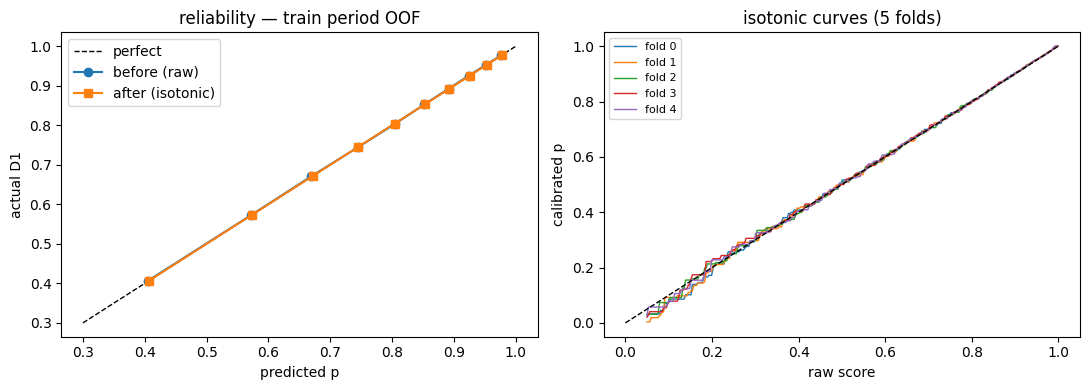


변수 중요도 (gain 비중, 모델 5개 평균, 상위 15개):
act_days            0.6152
days_since_last     0.0916
weekend_ratio       0.0728
mins_per_day        0.0476
trend               0.0456
base_dow            0.0306
days_to_expire      0.0247
payment_method_id   0.0206
days_since_signup   0.0158
pct_full            0.0083
pct_unique          0.0054
is_auto_renew       0.0048
age                 0.0043
plan_list_price     0.0033
city                0.0025


In [10]:
# ── 1) 조각끼리 비슷하게 학습됐나 ───────────────────────────────────────
_log = pd.DataFrame(fit_log).set_index('조각')
print(_log.to_string(float_format='{:.4f}'.format))
print('AUC 편차 {:.4f}  (0.005 안이면 고른 것임)'.format(_log['AUC'].max() - _log['AUC'].min()))

# ── 2) 보정 전/후 신뢰도 — 학습 기간 전체(OOF 880만 행) ─────────────────
def reliability(p, truth, bins=10):
    """예측을 10분위로 나눠 칸마다 '예측 평균 vs 실제'를 비교함"""
    d = pd.DataFrame({'p': p, 'y': truth})
    d['칸'] = pd.qcut(d['p'], bins, labels=False, duplicates='drop')
    r = d.groupby('칸').agg(행=('p', 'size'), 예측=('p', 'mean'), 실제=('y', 'mean'))
    r['차이(%p)'] = (r['실제'] - r['예측']) * 100
    return r

_m   = is_train
_raw = reliability(oof_raw[_m], y[_m])
_cal = reliability(oof_cal[_m], y[_m])

print('\n' + '[보정 전] 평균 {:.4f} vs 실제 {:.4f}  (차이 {:+.4f}) / 분위별 최대 {:.2f}%p'.format(
    oof_raw[_m].mean(), y[_m].mean(), oof_raw[_m].mean() - y[_m].mean(), _raw['차이(%p)'].abs().max()))
print(_raw.to_string(float_format='{:.4f}'.format))

print('\n' + '[보정 후] 평균 {:.4f} vs 실제 {:.4f}  (차이 {:+.4f}) / 분위별 최대 {:.2f}%p'.format(
    oof_cal[_m].mean(), y[_m].mean(), oof_cal[_m].mean() - y[_m].mean(), _cal['차이(%p)'].abs().max())
      + '   <- 이소토닉을 적합한 바로 그 데이터라 낙관적임 (아래 3)에서 정직하게 다시 잼)')
print(_cal.to_string(float_format='{:.4f}'.format))

print('\n' + '로그손실  보정 전 {:.5f} -> 후 {:.5f}   Brier  {:.5f} -> {:.5f}'.format(
    log_loss(y[_m], oof_raw[_m]), log_loss(y[_m], oof_cal[_m]),
    brier_score_loss(y[_m], oof_raw[_m]), brier_score_loss(y[_m], oof_cal[_m])))

# ── 3) 이소토닉 효과를 정직하게 재기 — 보정 조각을 유저 기준 반으로 쪼갬 ─
# 한쪽으로 곡선을 그리고 다른 쪽에서 평가함. 적합에 쓴 데이터로 재면 좋게 나오므로 이게 진짜 값임
# 조각 번호와 무관한 별도의 난수로 유저를 반반 나눔
# (fold_of_user 의 홀짝으로 나누면 한 조각 안의 유저가 전부 같은 쪽으로 몰려 한쪽이 비게 됨)
_half = np.random.default_rng(SEED + 1).integers(0, 2, size=n_user).astype(bool)[mart['u'].to_numpy()]
_hr, _hc = [], []
for i in range(5):
    a = is_train & (fold == i) &  _half                  # 곡선을 그리는 쪽
    b = is_train & (fold == i) & ~_half                  # 재는 쪽
    _iso = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0).fit(oof_raw[a], y[a])
    _hr.append(reliability(oof_raw[b], y[b])['차이(%p)'].abs().max())
    _hc.append(reliability(_iso.predict(oof_raw[b]), y[b])['차이(%p)'].abs().max())
print('\n' + '정직한 비교 (곡선은 절반으로 그리고 나머지 절반에서 잼, 조각 5개 평균):')
print('  분위별 최대 어긋남   보정 전 {:.2f}%p  ->  보정 후 {:.2f}%p'.format(np.mean(_hr), np.mean(_hc)))

# ── 4) 보정 곡선 그림 ───────────────────────────────────────────────────
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0.3, 1], [0.3, 1], 'k--', lw=1, label='perfect')
ax[0].plot(_raw['예측'], _raw['실제'], 'o-', label='before (raw)')
ax[0].plot(_cal['예측'], _cal['실제'], 's-', label='after (isotonic)')
ax[0].set_xlabel('predicted p'); ax[0].set_ylabel('actual D1'); ax[0].legend()
ax[0].set_title('reliability — train period OOF')
_xs = np.linspace(0.05, 0.999, 300)
for i, iso in enumerate(isos):
    ax[1].plot(_xs, iso.predict(_xs), lw=1, label='fold {}'.format(i))
ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
ax[1].set_xlabel('raw score'); ax[1].set_ylabel('calibrated p'); ax[1].legend(fontsize=8)
ax[1].set_title('isotonic curves (5 folds)')
plt.tight_layout(); plt.show()

# ── 5) 변수 중요도 (모델 5개 평균) ──────────────────────────────────────
# act_days 와 no_habit 은 act_days==0 일 때 완전히 같은 변수라 둘의 gain 을 합쳐서 봐야 함
_imp = pd.concat([pd.Series(b.feature_importance('gain'), index=b.feature_name())
                  for b in boosters], axis=1).mean(axis=1).sort_values(ascending=False)
print('\n' + '변수 중요도 (gain 비중, 모델 5개 평균, 상위 15개):')
print((_imp / _imp.sum()).head(15).to_string(float_format='{:.4f}'.format))
assert 'day' not in _imp.index, 'day 가 모델에 들어갔음 — 달력 날짜는 넣으면 안 됨'

## 4. 평가 기간 기대값 p · 편차

3절에서 만든 **보정 모델 5개**로 모든 행의 **기대값 p** 를 구하고, **편차 = 실제(0/1) − p** 를 계산함.
이 편차가 다음 단계(빔 서치)에서 집단을 고르는 **점수**가 됨.

### 행에 따라 p 를 구하는 방법이 다름

| 구간 | p 를 만드는 법 | 왜 |
|---|---|---|
| **평가** 3/16~3/30 | **보정 모델 5개 예측의 평균** | 설계대로(계획서 그림 1). 모든 유저가 "나를 본 모델 4개 + 안 본 모델 1개"로 **같은 조건**이 됨 |
| **학습** 3/1~3/15 | 그 유저를 **안 본 모델 하나**의 예측 (OOF) | 5개 평균을 쓰면 자기가 배운 행을 맞히는 셈이라 p 가 낙관적이 됨 |

학습 기간 p 도 구하는 이유는 **기준일별 그림을 30일 전체로 그려서**, 평가 기간의 편차가
원래 있던 것인지 새로 생긴 것인지 눈으로 보기 위함임.

### 편차를 읽는 규칙

| | |
|---|---|
| 부호 | **음수 = 기대보다 덜 돌아옴** (찾는 방향). 양수는 기대보다 더 돌아온 것 |
| 단위 | 개인은 −1 ~ +1 이지만 **개인 값은 해석하지 않음**. 집단 평균(%p)과 합("잃어버린 유저 수")으로만 봄 |
| 0이 아닌 게 정상 | 평가 기간 전체 편차가 0이 아닌 것은 **당연함** — 그 차이를 찾는 게 이 연구임 |

### 이 절에서 확인할 것

| # | 확인 | 통과 기준 |
|---|---|---|
| 1 | 학습 기간 편차 | **0 근처** (−0.07%p 안팎). 여기가 틀어지면 자(尺) 자체가 잘못된 것 |
| 2 | 기준일별 p vs 실제 | p 선이 실제 선의 오르내림(요일)을 따라가야 함 |
| 3 | **3/30** | 혼자 아래로 처져야 함 — 월말 효과가 아니라 **데이터 경계 효과**(결과일 3/31의 DAU가 −3.9%, 『EDA 정리』 4.3절) |
| 4 | **`no_habit` 집단** | 평균 편차가 **0 근처**여야 함. 이 집단은 비중이 학습 2.77% → 평가 4.73%로 늘어난 **생존 효과** 집단이라, 여기가 크게 양수면 `days_since_signup` 이 흡수를 못 한 것임 |
| 5 | 분류 지표 | **참고용**. 모델 선택에는 쓰지 않음 (3절 설명 참고) |

#### 왜 학습 기간만 모델 하나로 예측하나 — 층이 셋임

누수와 섞이기 쉬운데, 서로 다른 문제임.

| | 누수 | OOF 를 쓰는 이유 |
|---|---|---|
| 질문 | **미래 정보를 썼나?** | **그 행으로 자기를 평가해도 되나?** |
| 판단 기준 | **시점** | **그 행을 학습에 썼나** |
| 어기면 | 방법이 **틀림** | 측정이 **부풀려짐** |

같은 유저가 학습 기간에도 평가 기간에도 나오는 것은 **첫 번째 기준**으로 본다 → 시점이 다르므로
**누수가 아님**. 오히려 "이 사람이 원래 이랬는데 지금 덜 온다"를 말하려면 같은 사람을 전후로 봐야 함.

OOF 는 **두 번째 문제**임. 시험으로 비유하면,

| 상황 | 문제인가 |
|---|---|
| 같은 학생이 중간고사도 보고 기말고사도 봄 | ❌ 정상 ← 같은 유저가 두 기간에 나오는 것 |
| **중간고사 문제를 미리 가르쳐주고** 그 문제로 채점 | ✅ 실력을 못 잼 ← 학습에 쓴 행을 5개 평균으로 예측 |

행 단위로 보면 분명해짐.

| | 평가 기간 행 (민수 3/20) | 학습 기간 행 (민수 3/5) |
|---|---|---|
| 모델 0~4 중 **이 행**을 학습한 모델 | **없음** (날짜가 다름) | **4개** |
| 그래서 | 5개 전부 공정 → **평균** | 답을 아는 4개를 빼고 → **1개만** |

민수 3/5 행을 학습한 모델은 "민수가 3/5에 돌아왔다"는 정답을 이미 봤음. 그 모델로 민수 3/5 를
예측하면 당연히 잘 맞아 편차가 가짜로 0에 가까워지고, **"자가 맞는가"를 확인하는 점검 자체가
무의미해짐**. 유저 단위로 조각을 나눈 것도 이 때문임 — 민수의 3/5 행만 빼고 나머지 열네 행으로
학습하면 설명 변수가 거의 같아서(습관·특성은 완전히 동일) 사실상 외운 것이 되기 때문임.

**정리하면**

| 층 | 무엇을 막나 | 이 노트북에서 |
|---|---|---|
| 1 | **누수** — 미래 정보 사용 | 설명 변수가 전부 기준일 t 이하 (`build_mart.ipynb` 6절 assert) |
| 2 | **측정 공정성** — 학습에 쓴 행으로 자기를 잼 | 학습 기간은 OOF |
| 3 | (2)가 새는 것 — 같은 유저의 다른 행 | 유저 단위 5조각 |

#### 평가 기간이 유저를 아는 것은 괜찮나

괜찮을 뿐 아니라 **필요함**. 모델이 민수에 대해 아는 것은 전부 3/1~3/15 의 정보이고, 3/20 행
입장에서는 전부 과거임. 시점 기준으로 깨끗함. 그리고 "민수가 평소 얼마나 돌아오는 사람인가"를
잘 알수록 기대값이 정확해지는데, 그래야 "평소보다 덜 돌아왔다"를 말할 수 있음.

⚠️ 다만 한 가지 비대칭이 남음 — 보정 곡선은 **그 유저를 본 적 없는** 예측으로 그렸는데, 평가
기간에서는 **5개 중 4개가 그 유저를 아는** 예측에 적용됨. 방향은 예측 가능함(보정이 살짝
보수적으로 걸림). 학습 기간 편차가 0인지로 확인함.

#### 기간으로 자르는 것을 유저로 바꾸면 안 되는 이유

학습/평가를 **기간**이 아니라 유저로 나누면 이 연구가 성립하지 않음.

| | 기간 분할 (이 설계) | 유저 분할로 바꾸면 |
|---|---|---|
| 편차의 뜻 | "이 집단이 **평소보다** 덜 돌아왔다" | "모델이 이 집단을 못 맞힌다" |
| 시간 | 정상 기간 → 평가 기간 변화 | 없음 |
| 연구 기여 | EMRM 을 리텐션 하락 진단으로 확장 | **그냥 EMRM** |
| 주입 실험 | 평가 기간 결과만 바꿔 정답을 심음 | 심을 기간이 없어 불가능 |

유저 단위 분할은 **학습 기간 안에서만** 쓰는 내부 장치이고, 기간 분할과는 층이 다름.

In [11]:
import os, pickle
_t0 = time.time()

MODEL_DIR = 'data/model'

# ── 1) 저장된 모델을 불러옴 (커널을 새로 켜도 3절을 다시 안 돌려도 됨) ──
boosters = [lgb.Booster(model_file='{}/lgb_fold{}.txt'.format(MODEL_DIR, i)) for i in range(5)]
with open('{}/isotonic.pkl'.format(MODEL_DIR), 'rb') as f:
    isos = pickle.load(f)
print('모델 {}개, 보정 곡선 {}개 불러옴'.format(len(boosters), len(isos)))

p = np.full(len(mart), np.nan, dtype='float32')

# ── 2) 평가 기간 — 보정 모델 5개의 평균 ─────────────────────────────────
X_ev = mart.loc[is_eval, FEATURES]
_acc = np.zeros(int(is_eval.sum()), dtype='float64')
for i in range(5):
    _acc += isos[i].predict(boosters[i].predict(X_ev))
    print('  평가 기간 — 모델 {} 끝 ({:.1f}분)'.format(i, (time.time() - _t0) / 60))
p[is_eval] = (_acc / 5).astype('float32')
del X_ev, _acc

# ── 3) 학습 기간 — 그 유저를 안 본 모델 하나로만 (OOF) ──────────────────
# 5개 평균을 쓰면 자기가 배운 행을 맞히는 셈이라 p 가 낙관적으로 나옴
for i in range(5):
    m_ = is_train & (fold == i)
    p[m_] = isos[i].predict(boosters[i].predict(mart.loc[m_, FEATURES])).astype('float32')
print('  학습 기간 OOF 끝 ({:.1f}분)'.format((time.time() - _t0) / 60))

# ── 4) 편차 = 실제 − 기대 ───────────────────────────────────────────────
dev = (y.astype('float32') - p)

assert not np.isnan(p).any(), 'p 가 비어 있는 행이 있음'
print('\n전체 {:.1f}분.  p 범위 {:.4f} ~ {:.4f}'.format(
    (time.time() - _t0) / 60, p.min(), p.max()))

모델 5개, 보정 곡선 5개 불러옴
  평가 기간 — 모델 0 끝 (1.1분)
  평가 기간 — 모델 1 끝 (2.2분)
  평가 기간 — 모델 2 끝 (3.5분)
  평가 기간 — 모델 3 끝 (4.9분)
  평가 기간 — 모델 4 끝 (6.1분)
  학습 기간 OOF 끝 (7.4분)

전체 7.4분.  p 범위 0.0000 ~ 1.0000


#### 분류 지표(정확도·정밀도·재현율)를 보조로만 쓰는 이유

아래 셀에서 함께 찍지만 **모델을 고르는 데는 쓰지 않음**. 판단 기준은 로그손실·Brier·신뢰도 표임.

이 지표들은 **"돌아온다/안 돌아온다"로 잘라서** 세는 지표인데, 이 연구가 쓰는 것은 잘린 0/1 이
아니라 **확률 p 자체**임. 편차 = 실제 − p 이고 집단 평균 편차를 1%p 단위로 읽음.

| | |
|---|---|
| **임계값이 임의적** | 0.5 로 자르면 D1 이 78%라 인원의 92.5%를 "돌아온다"로 찍게 됨. 예측 확률 0.41 인 사람과 0.98 인 사람이 같은 칸에 들어가 구분이 사라짐 |
| **바닥값이 높음** | 아무 모델 없이 전원 "돌아온다"로 찍어도 정확도 0.777. 모델이 그보다 나아도 1.7%p 차이로만 보임 (같은 모델의 로그손실은 0.528 → 0.437 로 17% 좋아짐) |
| **확률의 수준을 못 봄** | 모든 p 에 0.05 를 더해도 순위가 그대로라 **AUC 는 정확히 같고 정확도도 거의 안 변함**. 그런데 편차는 전부 −5%p 가 되어 **없던 하락이 생김**. 막아야 하는 것이 바로 이것임 |

그래도 적어 두는 이유는 ① 포트폴리오에서 익숙한 지표를 찾는 사람이 있고 ② 다른 리텐션 예측
연구가 보통 AUC·F1 을 보고하므로 **비교할 공통 자**가 필요하기 때문임.

#### 종속변수가 불균형한 것은 아님

D1 이 78% 라 "돌아온 사람이 너무 많은 것 아닌가" 싶지만, 소수 쪽(안 돌아옴)이 학습 기간에만
**194만 행**임. 불균형이 문제가 되는 것은 소수 클래스가 1% 아래로 떨어져 패턴을 볼 표본이
모자랄 때임. 또 신뢰도 표에서 맨 아래 칸은 41%만, 맨 위 칸은 98%가 돌아오므로 모델이 사람을
**56.8%p 폭으로 가르고 있음** — 뭉개고 있는 것이 아님.

⚠️ **그래서 `is_unbalance` · `scale_pos_weight` · 언더/오버샘플링 · SMOTE 를 쓰지 않음.**
양성 비율을 1:1 로 맞추면 모델이 배우는 기준선이 0.78 에서 0.50 으로 내려가 **전 집단에
+28%p 짜리 가짜 상승 편차**가 깔림. 찾으려는 하락이 1~5%p 인데 그보다 훨씬 큰 왜곡임.

구간                        행       실제     기대 p     편차(%p)       편차 합(명)
학습 3/1~3/15       8,802,984   0.7796   0.7796      -0.00            -4
평가 3/16~3/30      9,015,648   0.7836   0.7711      +1.25       112,400

기준일별:
   날짜  요일 구간      행     실제     기대  편차(%p)
03/01 Wed 학습 575889 0.7943 0.8025 -0.8175
03/02 Thu 학습 580623 0.7926 0.7964 -0.3805
03/03 Fri 학습 590594 0.7516 0.7566 -0.4908
03/04 Sat 학습 584124 0.7669 0.7713 -0.4453
03/05 Sun 학습 589177 0.7450 0.7502 -0.5261
03/06 Mon 학습 577955 0.7906 0.7954 -0.4775
03/07 Tue 학습 579079 0.7933 0.7979 -0.4612
03/08 Wed 학습 581288 0.7962 0.7961  0.0095
03/09 Thu 학습 584919 0.7941 0.7909  0.3246
03/10 Fri 학습 597915 0.7561 0.7517  0.4418
03/11 Sat 학습 592497 0.7728 0.7671  0.5738
03/12 Sun 학습 598768 0.7503 0.7460  0.4356
03/13 Mon 학습 587823 0.7943 0.7902  0.4170
03/14 Tue 학습 589627 0.7992 0.7933  0.5811
03/15 Wed 학습 592706 0.7990 0.7915  0.7528
03/16 Thu 평가 595837 0.7993 0.7862  1.3097
03/17 Fri 평가 608931 0.7561 0.7475  0.8591
03/18 Sat 평가 597723 0.77

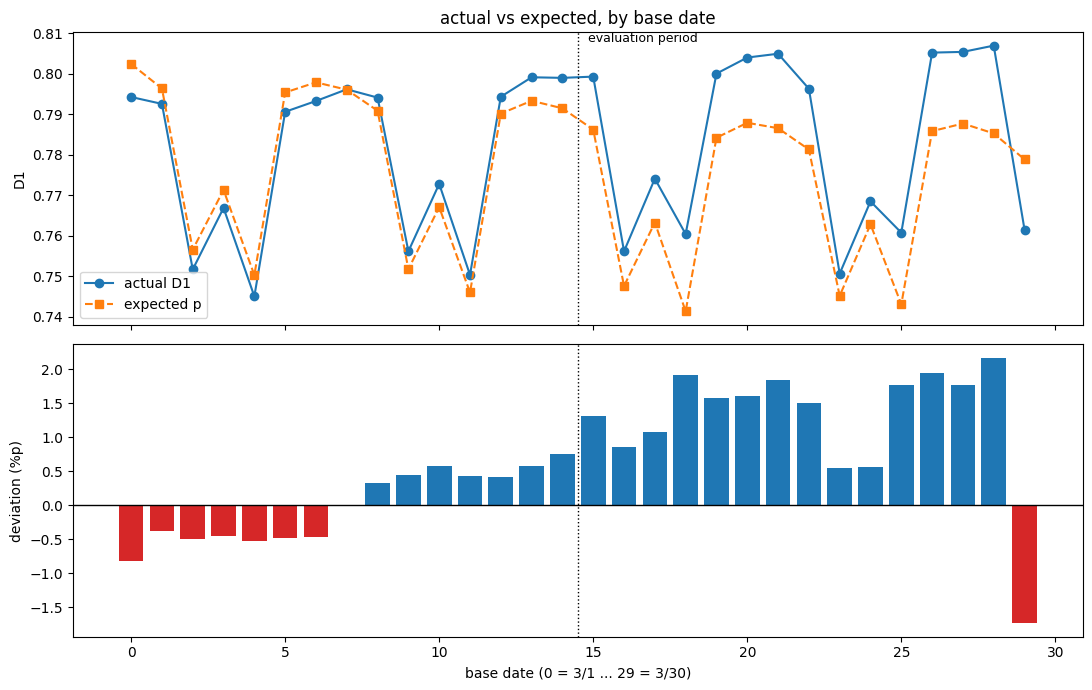


[no_habit (2월 활동 없음)] 평가 기간 집단별 편차:
             행     비중  편차(%p)
k                            
False  8589645 0.9527  1.1124
True    426003 0.0473  3.9557

[has_tx (거래 기록)] 평가 기간 집단별 편차:
             행     비중  편차(%p)
k                            
False   119639 0.0133 -0.3628
True   8896009 0.9867  1.2684

[days_since_signup] 평가 기간 집단별 편차:
              행     비중  편차(%p)
k                             
신규(3월)    31350 0.0035 -1.5650
1개월      216770 0.0240  2.8633
1년      1543530 0.1712  1.5031
3년      2730322 0.3028  1.1876
3년+     4493500 0.4984  1.1363

[base_dow (기준일 요일)] 평가 기간 집단별 편차:
         행     비중  편차(%p)
k                        
금  1217409 0.1350  0.7041
목  1809610 0.2007  0.3515
수  1206907 0.1339  2.0058
월  1195716 0.1326  1.7619
일  1195543 0.1326  1.8418
토  1187964 0.1318  0.8272
화  1202499 0.1334  1.6920

평가 기간 참고 지표 (판단 기준은 앞의 셋, 뒤의 넷은 보고용):
  AUC 0.7621  로그손실 0.44632  Brier 0.14399   |   정확도 0.7940  정밀도 0.8210  재현율 0.9427  F1 0.8776


In [12]:
# ── 1) 구간별 — 학습 기간 편차가 0 근처여야 자가 맞는 것임 ──────────────
print('{:<16s}{:>11s}{:>9s}{:>9s}{:>11s}{:>14s}'.format(
    '구간', '행', '실제', '기대 p', '편차(%p)', '편차 합(명)'))
for 이름, m_ in [('학습 3/1~3/15', is_train), ('평가 3/16~3/30', is_eval)]:
    print('{:<16s}{:>11,}{:>9.4f}{:>9.4f}{:>+11.2f}{:>14,.0f}'.format(
        이름, int(m_.sum()), y[m_].mean(), p[m_].mean(), dev[m_].mean() * 100, dev[m_].sum()))

# ── 2) 기준일별 — p 가 실제의 요일 오르내림을 따라가나 ──────────────────
_d = pd.DataFrame({'day': mart['day'].to_numpy(), '실제': y, 'p': p, 'dev': dev})
_g = _d.groupby('day').agg(행=('실제', 'size'), 실제=('실제', 'mean'),
                           기대=('p', 'mean'), 편차=('dev', 'mean'))
_g['편차(%p)'] = _g['편차'] * 100
_g['날짜'] = (pd.Timestamp('2017-03-01') + pd.to_timedelta(_g.index, unit='D')).strftime('%m/%d')
_g['요일'] = (pd.Timestamp('2017-03-01') + pd.to_timedelta(_g.index, unit='D')).day_name().str[:3]
_g['구간'] = np.where(_g.index <= TRAIN_LAST, '학습', '평가')
print('\n기준일별:')
print(_g[['날짜', '요일', '구간', '행', '실제', '기대', '편차(%p)']].to_string(
    index=False, float_format='{:.4f}'.format))

# ── 3) 그림 ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
_x = _g.index
ax[0].plot(_x, _g['실제'], 'o-', label='actual D1')
ax[0].plot(_x, _g['기대'], 's--', label='expected p')
ax[0].axvline(TRAIN_LAST + 0.5, color='k', lw=1, ls=':')
ax[0].text(TRAIN_LAST + 0.7, ax[0].get_ylim()[1], ' evaluation period', va='top', fontsize=9)
ax[0].set_ylabel('D1'); ax[0].legend(); ax[0].set_title('actual vs expected, by base date')
ax[1].bar(_x, _g['편차(%p)'], color=np.where(_g['편차(%p)'] < 0, 'tab:red', 'tab:blue'))
ax[1].axhline(0, color='k', lw=1)
ax[1].axvline(TRAIN_LAST + 0.5, color='k', lw=1, ls=':')
ax[1].set_xlabel('base date (0 = 3/1 ... 29 = 3/30)'); ax[1].set_ylabel('deviation (%p)')
plt.tight_layout(); plt.show()

# ── 4) 집단별 평균 편차 — 기대 모델이 알려진 구성 변화를 흡수했나 ───────
# no_habit 이 핵심임: 비중이 학습 2.77% -> 평가 4.73% 로 늘어난 생존 효과 집단이라,
# days_since_signup 이 흡수하지 못했으면 여기가 크게 양수로 뜸
def by_group(col, label):
    g = (pd.DataFrame({'k': col, 'dev': dev, 'ev': is_eval})
         .query('ev').groupby('k', observed=True)['dev']
         .agg(행='size', 편차='mean'))
    g['편차(%p)'] = g['편차'] * 100
    g['비중'] = g['행'] / g['행'].sum()
    print('\n[{}] 평가 기간 집단별 편차:'.format(label))
    print(g[['행', '비중', '편차(%p)']].to_string(float_format='{:.4f}'.format))

by_group(mart['no_habit'].to_numpy(), 'no_habit (2월 활동 없음)')
by_group(mart['has_tx'].to_numpy(), 'has_tx (거래 기록)')
by_group(pd.cut(mart['days_since_signup'], [-np.inf, 0, 30, 365, 1095, np.inf],
                labels=['신규(3월)', '1개월', '1년', '3년', '3년+']), 'days_since_signup')
by_group(mart['base_dow'].map({0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}),
         'base_dow (기준일 요일)')

# ── 5) 참고용 지표 — 모델 선택에는 쓰지 않음 (3절 마크다운 참고) ────────
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
_pe, _ye = p[is_eval], y[is_eval]
print('\n평가 기간 참고 지표 (판단 기준은 앞의 셋, 뒤의 넷은 보고용):')
print('  AUC {:.4f}  로그손실 {:.5f}  Brier {:.5f}   |   정확도 {:.4f}  정밀도 {:.4f}  재현율 {:.4f}  F1 {:.4f}'.format(
    roc_auc_score(_ye, _pe), log_loss(_ye, _pe), brier_score_loss(_ye, _pe),
    accuracy_score(_ye, _pe >= 0.5), precision_score(_ye, _pe >= 0.5),
    recall_score(_ye, _pe >= 0.5), f1_score(_ye, _pe >= 0.5)))

In [13]:
# ── 저장 — 다음 단계(빔 서치)는 이 파일만 읽으면 됨 ─────────────────────
pred = pd.DataFrame({'u'   : mart['u'].to_numpy(),
                     'day' : mart['day'].to_numpy(),
                     'd1'  : y,
                     'fold': fold,
                     'p'   : p,
                     'dev' : dev})
pred.to_parquet('data/pred.parquet', compression='zstd', index=False)

print('data/pred.parquet  {:,}행 x {}열  ({:.0f}MB)'.format(
    len(pred), pred.shape[1], os.path.getsize('data/pred.parquet') / 1e6))
print('\n열: u(유저 번호) / day(기준일 0=3/1) / d1(실제) / fold(조각) / p(기대값) / dev(편차 = d1 - p)')
pred.head()

data/pred.parquet  17,818,632행 x 6열  (190MB)

열: u(유저 번호) / day(기준일 0=3/1) / d1(실제) / fold(조각) / p(기대값) / dev(편차 = d1 - p)


,u,day,d1,fold,p,dev
0,1,29,False,2,0.712050,-0.712050
1,6,29,True,2,0.632766,0.367234
2,11,23,True,2,0.891439,0.108561
3,12,24,False,2,0.841086,-0.841086
4,13,23,True,2,0.624819,0.375181


### 편차가 날짜를 따라 기울어지는 이유 — 습관 정보의 '노후화'가 아니라 '생존 선택'

4절에서 편차가 3/1 −0.82%p 에서 3/29 +2.17%p 로 거의 선형으로 오르는 것을 봤음. 그럴듯한 설명이
두 가지인데, 아래 셀의 표가 둘 중 하나를 **기각**함.

| 가설 | 예상되는 모습 |
|---|---|
| **① 노후화** — 2월 습관 정보가 시간이 갈수록 낡아짐 | 습관이 가볍든 무겁든 **모든 집단에서 고르게** 벌어져야 함 |
| **② 생존 선택** — 날이 갈수록 그날 활동한 사람이 충성도 높은 쪽으로 걸러짐 | **가벼운 집단에만** 몰려야 함. 무거운 집단은 걸러낼 사람이 없음 |

측정 결과는 **②** 임.

| 2월 활동일 | 3/1 | 3/15 | 3/29 | 기울기 |
|---|---|---|---|---|
| **21~28일 (헤비, 52%)** | +0.19 | −0.02 | +0.22 | **−0.00%p/일** |
| 11~20일 (29%) | −1.35 | +1.05 | +2.93 | +0.14 |
| 4~10일 (11%) | −3.73 | +2.61 | +6.16 | +0.29 |
| 0 (미측정, 4.7%) | −7.53 | +2.01 | +5.75 | +0.32 |
| **1~3일 (가벼움, 2.9%)** | −3.18 | +4.12 | **+9.01** | **+0.43** |

**헤비 유저는 29일 동안 기울기가 정확히 0임.** 정보가 그냥 낡아가는 것이라면 이들도 같이 벌어져야
하는데 전혀 안 벌어짐 → ① 기각.

#### 왜 가벼운 집단에만 생기나

2월에 1~3일만 들은 사람 중에서,

| | 모델의 예측 |
|---|---|
| **3월 초**에 나타나는 사람 | 곧 이탈할 사람이 잔뜩 섞여 있음 → **과대 예측** (−3.18%p) |
| **3월 말**까지 남아 있는 사람 | 그중 끝까지 버틴 유독 충성도 높은 소수 → **과소 예측** (+9.01%p) |

모델이 아는 것은 "2월에 1~3일 들었다" 뿐이라 이 둘을 구분할 수 없음. 반면 2월에 21~28일 들은
사람은 **걸러낼 사람이 애초에 없어서** 이 현상이 안 생김.

즉 편차가 평행 이동하는 것이 아니라 **3월 중순을 축으로 회전**하고 있음.

#### 전체 +1.25%p 는 어디서 오나

| 집단 | 비중 | 편차 | **기여** |
|---|---|---|---|
| **11~20일** | 29.4% | +1.95%p | **+0.57%p** |
| 4~10일 | 10.8% | +4.17%p | +0.45%p |
| 1~3일 | 2.9% | +6.69%p | +0.19%p |
| 0 (미측정) | 4.7% | +3.96%p | +0.19%p |
| 21~28일 | 52.3% | −0.29%p | −0.15%p |

(평가 기간 **전체** 기준이라 3/30 이 들어 있음. 합계 +1.25%p. 위의 기울기 표는 추세를 보는 것이라
데이터 경계 효과가 있는 3/30 을 뺐으므로, 두 표의 숫자가 조금 다름)

가장 심한 것은 1~3일 집단이지만, **전체를 밀어올리는 것은 중간층(11~20일)** 임 — 비중이 커서임.
이 때문에 "날짜별로 전체 평균을 빼는" 보정만으로는 부족함. 전체 기준선은 0이 되지만
**집단 간 차이는 그대로 남아**, 가볍게 듣는 집단의 진짜 하락이 가려짐.

In [14]:
# ── 습관 집단 x 날짜로 편차 기울기를 재어 두 가설을 가름 ────────────────
# 노후화라면 모든 집단에서 고르게 벌어지고, 생존 선택이라면 가벼운 집단에만 몰림
_b = pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28],
            labels=['0 (미측정)', '1-3일', '4-10일', '11-20일', '21-28일'])
_s = pd.DataFrame({'day': mart['day'].to_numpy(), 'dev': dev, 'b': _b.to_numpy()})
_s = _s[_s['day'] <= 28]                       # 3/30 은 데이터 경계 효과라 추세에서 뺌

_piv = _s.pivot_table(index='b', columns='day', values='dev', aggfunc='mean', observed=True) * 100
_out = _piv[[0, 14, 28]].copy()
_out.columns = ['3/01', '3/15', '3/29']
_out['기울기(%p/일)'] = [np.polyfit(_piv.columns.to_numpy(), _piv.loc[i].to_numpy(), 1)[0]
                      for i in _piv.index]
print('습관 집단별 편차의 날짜 기울기 (3/30 제외):')
print(_out.to_string(float_format='{:.2f}'.format))
print('  → 헤비(21-28일)가 0 이고 가벼울수록 커지면 "생존 선택", 고르게 벌어지면 "노후화"')

# ── 전체 편차를 집단별 기여로 쪼갬 (비중 x 편차) ────────────────────────
_e = pd.DataFrame({'b': _b.to_numpy()[is_eval], 'dev': dev[is_eval]}) \
       .groupby('b', observed=True).agg(행=('dev', 'size'), 편차=('dev', 'mean'))
_e['비중'] = _e['행'] / _e['행'].sum()
_e['편차(%p)'] = _e['편차'] * 100
_e['기여(%p)'] = _e['비중'] * _e['편차(%p)']
print('\n평가 기간 편차의 출처 (기여 = 비중 x 편차):')
print(_e[['행', '비중', '편차(%p)', '기여(%p)']].sort_values('기여(%p)', ascending=False)
        .to_string(float_format='{:.4f}'.format))
print('  합계 {:.3f}%p'.format(_e['기여(%p)'].sum()))

습관 집단별 편차의 날짜 기울기 (3/30 제외):
         3/01  3/15  3/29  기울기(%p/일)
b                                   
0 (미측정) -7.53  2.01  5.75       0.32
1-3일    -3.18  4.12  9.01       0.43
11-20일  -1.35  1.05  2.93       0.14
21-28일   0.19 -0.02  0.22      -0.00
4-10일   -3.73  2.61  6.16       0.29
  → 헤비(21-28일)가 0 이고 가벼울수록 커지면 "생존 선택", 고르게 벌어지면 "노후화"

평가 기간 편차의 출처 (기여 = 비중 x 편차):
               행     비중  편차(%p)  기여(%p)
b                                      
11-20일   2646756 0.2936  1.9476  0.5718
4-10일     973767 0.1080  4.1740  0.4508
1-3일      257674 0.0286  6.6926  0.1913
0 (미측정)   426003 0.0473  3.9557  0.1869
21-28일   4711448 0.5226 -0.2948 -0.1541
  합계 1.247%p


## 5. 실험 — `days_since_first_mar` 를 넣으면 기준선 표류가 줄어드나

### 무엇을 고치려는 것인가

4절에서 **편차가 날짜를 따라 기울어지는 것**을 확인했음 (3/1 −0.82%p → 3/29 +2.17%p, 평가 기간 평균 +1.25%p).
원인은 **생존 선택**임 — 2월에 가볍게 들은 유저 중 3월 말까지 남은 사람은 유독 충성도가 높은데,
습관(D)은 2월 스냅샷이라 이를 모름. 실제로 기울기가 습관에 따라 완전히 갈림.

집단별 기울기는 **4절 끝의 "편차가 날짜를 따라 기울어지는 이유"** 에 정리돼 있음 —
헤비 유저(52%)는 **−0.00%p/일로 평평**하고 1~3일 집단만 **+0.43%p/일** 임.

`days_since_first_mar`(기준일 − 3월 첫 활동일)는 **그 사람이 3월 들어 얼마나 오래 살아남았는지**를
직접 재는 변수임. 첫 활동일이 과거에 고정이라 이벤트로 생긴 행동 감소를 흡수하지 않음.

### 그런데 위험이 둘 있음 (10/7 측정)

| 위험 | 수치 |
|---|---|
| **달력 날짜를 복원함** | 3/1부터 활동한 유저는 이 값이 기준일 번호와 **같음** — 전체 행의 **72.3%** |
| **외삽을 못 함** | 학습 기간에는 0~14 만 나오는데 평가 기간 행의 **90.9%** 가 14를 넘음 |

첫 번째가 특히 위험함. 모델이 달력 날짜를 외우기 시작하면 **학습 기간 편차는 더 예뻐지는데
평가 기간의 진짜 하락까지 삼킴**. 그래서 "표류가 줄었나"만 보면 안 되고 **자(尺)가 망가지지
않았는지**를 같이 봐야 함.

### 실험 방법 — 조각 하나로 먼저 봄

전체 5조각은 30분이 걸리므로, **조각 0 하나만** 변형 모델로 학습해 먼저 비교함(약 7분).
비교 상대도 **조각 0 모델 하나**로 맞춰 조건을 같게 함(5개 평균과 섞지 않음).

| | 기본 | 변형 |
|---|---|---|
| 변수 | 23개 | **24개** (`days_since_first_mar` 추가) |
| 모델 | 이미 있는 `boosters[0]` · `isos[0]` | 새로 학습 |

### 볼 것 네 가지

| # | 확인 | 좋은 결과 | 나쁜 신호 |
|---|---|---|---|
| 1 | 평가 기간 평균 편차 | +1.25%p 에서 **0 쪽으로** 줄어듦 | 그대로이거나, **0을 지나 음수로** 내려감(과보정) |
| 2 | **날짜별 기울기** (학습·평가 따로) | 평가 기울기가 **0에 가까워짐** | 평가 기울기가 음수로 뒤집힘 |
| 3 | 습관 집단별 편차 | 1~3일·미측정 집단의 +6.76 / +3.98%p 가 줄어듦 | 21~28일 집단(원래 0)이 **망가짐** |
| 4 | 변수 중요도 | 새 변수가 쓰이되 `base_dow`·`days_since_signup` 이 **크게 안 밀림** | 둘이 크게 밀림 = 달력·시간 구조를 새 변수가 대신 떠안음 |

⚠️ **"학습 기간 평균 편차가 0인가"는 점검이 안 됨** — 이소토닉이 바로 그 데이터에 맞춰 적합되므로
어느 쪽이든 0이 나옴. 그래서 평균 대신 **날짜별 기울기**를 봄.

#### 이 실험으로 가릴 수 없는 것

모델은 **학습 기간(3/1~3/15)만** 보고 배우므로, 평가 기간에 주입할 하락을 **학습에서 볼 일이 없음**.
즉 "달력을 외워서 하락을 삼킨다"는 식으로는 일어나지 않음. 진짜 위험은 둘임.

| 위험 | 어떻게 드러나나 |
|---|---|
| **과보정** | 학습 기간 안의 상승 추세를 외워 평가 기간 p 를 지나치게 높게 잡음 → 편차가 음수로 내려감 (위 1·2번) |
| **일반화 안 됨** | 이 변수가 '생존 기간'이 아니라 **2017년 3월의 달력 효과**를 담은 것이라면, 다른 달·다른 데이터에서는 안 통함. 이건 수치로 못 가리고 **해석과 주입 실험(7.2)** 으로 판단해야 함 |

In [15]:
_t0 = time.time()

EXTRA  = ['days_since_first_mar']
FEAT2  = FEATURES + EXTRA                      # 24개
MODEL2 = 'data/model_dsfm'                     # 기본 모델(data/model/)은 건드리지 않음
os.makedirs(MODEL2, exist_ok=True)

# ── 조각 0 만 학습함 (기본 모델과 같은 조각·같은 설정값) ────────────────
tr = is_train & (fold != 0)
ca = is_train & (fold == 0)

ds_tr = lgb.Dataset(mart.loc[tr, FEAT2], label=y[tr], categorical_feature=CATS)
ds_ca = lgb.Dataset(mart.loc[ca, FEAT2], label=y[ca], categorical_feature=CATS, reference=ds_tr)

m2 = lgb.train(params, ds_tr, num_boost_round=1500,
               valid_sets=[ds_ca], valid_names=['보정조각'],
               callbacks=[lgb.early_stopping(50, verbose=False)])

s2   = m2.predict(mart.loc[ca, FEAT2], num_iteration=m2.best_iteration).astype('float32')
iso2 = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0).fit(s2, y[ca])
m2.save_model('{}/lgb_fold0.txt'.format(MODEL2), num_iteration=m2.best_iteration)
with open('{}/isotonic.pkl'.format(MODEL2), 'wb') as f:
    pickle.dump([iso2], f)

print('변형 모델  라운드 {:4d}  AUC {:.4f}  로그손실 {:.5f}  ({:.1f}분)'.format(
    m2.best_iteration, roc_auc_score(y[ca], s2), log_loss(y[ca], s2), (time.time() - _t0) / 60))
print('기본 모델  라운드 {:4d}  AUC {:.4f}  로그손실 {:.5f}'.format(
    boosters[0].num_trees(), roc_auc_score(y[ca], oof_raw[ca]), log_loss(y[ca], oof_raw[ca])))
del ds_tr, ds_ca

변형 모델  라운드  926  AUC 0.7853  로그손실 0.43300  (4.3분)
기본 모델  라운드  628  AUC 0.7812  로그손실 0.43657


예측 3.1분

구간                          기본(%p)      변형(%p)          변화
학습 조각0 (자 검증)               -0.000      -0.000      -0.000
평가 3/16~3/30                 1.234      -2.117      -3.351
  → 학습 조각0 의 평균이 0 인 것은 이소토닉이 그 데이터에 맞춰 적합됐기 때문임(당연함).
     의미 있는 것은 아래 날짜별 표 — 학습 기간 안의 기울기가 어떻게 변하는가임

날짜별 편차(%p):
        기본     변형     차이
day                     
0   -0.714  0.471  1.185
4   -0.515  0.171  0.685
9    0.514  0.007 -0.507
14   0.694 -0.295 -0.988
15   1.321 -1.164 -2.484
18   1.901 -2.529 -4.430
21   1.838 -0.519 -2.357
24   0.526 -3.007 -3.533
28   2.162 -0.424 -2.586

기울기(%p/일)
  학습 3/1~3/15      기본 +0.103  ->  변형 -0.043
  평가 3/16~3/29     기본 +0.042  ->  변형 +0.028
  전체               기본 +0.094  ->  변형 -0.101

습관 집단별 평가 기간 편차(%p):
               행     기본     변형     변화
b                                    
0 (미측정)   426003  3.883  0.010 -3.874
1-3일      257674  6.704 -2.728 -9.432
11-20일   2646756  1.944 -2.827 -4.771
21-28일   4711448 -0.281 -1.410 -1.129
4-10일     973767  4.027 -4.37

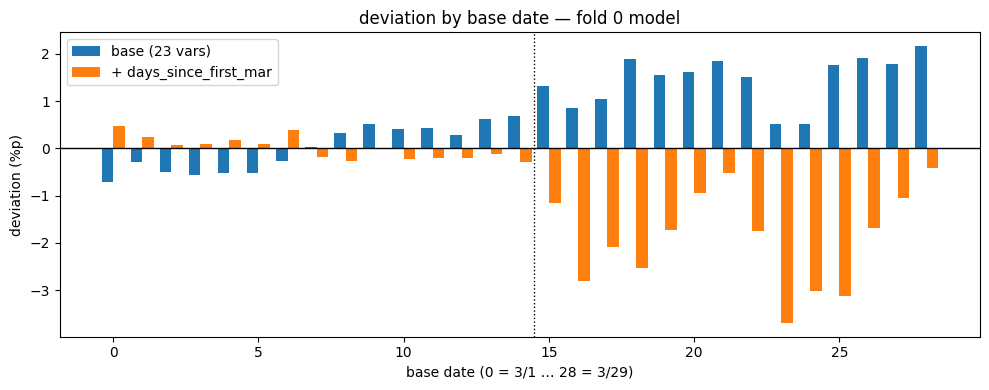

In [16]:
_t0 = time.time()

# ── 두 모델로 전 구간 p 를 구함 (조각 0 모델 하나씩, 조건을 같게 맞춤) ──
# 학습 기간은 조각 0 행만 봄 — 그 모델이 학습에 쓰지 않은 행이기 때문임
ev   = is_eval
ca0  = is_train & (fold == 0)

p_base = np.full(len(mart), np.nan, dtype='float32')
p_new  = np.full(len(mart), np.nan, dtype='float32')
for msk, cols in [(ev, None), (ca0, None)]:
    p_base[msk] = isos[0].predict(boosters[0].predict(mart.loc[msk, FEATURES])).astype('float32')
    p_new[msk]  = iso2.predict(m2.predict(mart.loc[msk, FEAT2])).astype('float32')
print('예측 {:.1f}분'.format((time.time() - _t0) / 60))

dev_base = y.astype('float32') - p_base
dev_new  = y.astype('float32') - p_new

# ── 1·3) 구간별 평균 편차 ───────────────────────────────────────────────
print('\n{:<22s}{:>12s}{:>12s}{:>12s}'.format('구간', '기본(%p)', '변형(%p)', '변화'))
for 이름, msk in [('학습 조각0 (자 검증)', ca0), ('평가 3/16~3/30', ev)]:
    b, n = dev_base[msk].mean() * 100, dev_new[msk].mean() * 100
    print('{:<22s}{:>12.3f}{:>12.3f}{:>12.3f}'.format(이름, b, n, n - b))
print('  → 학습 조각0 의 평균이 0 인 것은 이소토닉이 그 데이터에 맞춰 적합됐기 때문임(당연함).')
print('     의미 있는 것은 아래 날짜별 표 — 학습 기간 안의 기울기가 어떻게 변하는가임')

# ── 2) 날짜별 편차와 기울기 ─────────────────────────────────────────────
_d = pd.DataFrame({'day': mart['day'].to_numpy(), 'b': dev_base, 'n': dev_new})
_d = _d[(ev | ca0) & (mart['day'].to_numpy() <= 28)]          # 3/30(경계 효과) 제외
_g = _d.groupby('day').agg(기본=('b', 'mean'), 변형=('n', 'mean')) * 100
_g['차이'] = _g['변형'] - _g['기본']
print('\n날짜별 편차(%p):')
print(_g.loc[[0, 4, 9, 14, 15, 18, 21, 24, 28]].to_string(float_format='{:.3f}'.format))

_tr_x = _g.index[_g.index <= 14].to_numpy()
_ev_x = _g.index[_g.index > 14].to_numpy()
print('\n기울기(%p/일)')
for 이름, xs in [('학습 3/1~3/15', _tr_x), ('평가 3/16~3/29', _ev_x), ('전체', _g.index.to_numpy())]:
    _b = np.polyfit(xs, _g.loc[xs, '기본'].to_numpy(), 1)[0]
    _n = np.polyfit(xs, _g.loc[xs, '변형'].to_numpy(), 1)[0]
    print('  {:<16s} 기본 {:+.3f}  ->  변형 {:+.3f}'.format(이름, _b, _n))

# ── 습관 집단별 (평가 기간) ─────────────────────────────────────────────
_b = pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28],
            labels=['0 (미측정)', '1-3일', '4-10일', '11-20일', '21-28일'])
_t = pd.DataFrame({'b': _b.to_numpy()[ev], '기본': dev_base[ev], '변형': dev_new[ev]}) \
       .groupby('b', observed=True).agg(행=('기본', 'size'), 기본=('기본', 'mean'), 변형=('변형', 'mean'))
_t[['기본', '변형']] *= 100
_t['변화'] = _t['변형'] - _t['기본']
print('\n습관 집단별 평가 기간 편차(%p):')
print(_t.to_string(float_format='{:.3f}'.format))

# ── 4) 변수 중요도 ──────────────────────────────────────────────────────
_i1 = pd.Series(boosters[0].feature_importance('gain'), index=boosters[0].feature_name())
_i2 = pd.Series(m2.feature_importance('gain'), index=m2.feature_name())
# 새 변수는 기본 모델에 없어 NaN 이 되는데, 그대로 두면 정렬에서 밀려 표에 안 보임 → 0 으로 채움
_imp = pd.DataFrame({'기본': _i1 / _i1.sum(), '변형': _i2 / _i2.sum()}).fillna(0.0)
_imp['변화'] = _imp['변형'] - _imp['기본']
print('\n새 변수가 가져간 몫: {:.4f}   (base_dow {:.4f} -> {:.4f} / days_since_signup {:.4f} -> {:.4f})'.format(
    _imp.loc['days_since_first_mar', '변형'],
    _imp.loc['base_dow', '기본'], _imp.loc['base_dow', '변형'],
    _imp.loc['days_since_signup', '기본'], _imp.loc['days_since_signup', '변형']))
print('\n변수 중요도 (gain 비중) — 변형에서 많이 움직인 순 상위 8개:')
print(_imp.reindex(_imp['변화'].abs().sort_values(ascending=False).index).head(8)
      .to_string(float_format='{:.4f}'.format))

# ── 그림 ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(_g.index - 0.2, _g['기본'], width=0.4, label='base (23 vars)')
ax.bar(_g.index + 0.2, _g['변형'], width=0.4, label='+ days_since_first_mar')
ax.axhline(0, color='k', lw=1); ax.axvline(14.5, color='k', lw=1, ls=':')
ax.set_xlabel('base date (0 = 3/1 … 28 = 3/29)'); ax.set_ylabel('deviation (%p)')
ax.set_title('deviation by base date — fold 0 model'); ax.legend()
plt.tight_layout(); plt.show()

### 실험 결과 — **기각**. `days_since_first_mar` 는 넣지 않음

| 지표 | 기본 (23변수) | 변형 (24변수) | |
|---|---|---|---|
| 조각0 AUC | 0.7812 | **0.7853** | 예측력은 좋아짐 |
| 조각0 로그손실 | 0.43657 | **0.43300** | 예측력은 좋아짐 |
| 조각0 라운드 | 628 | 926 | |
| **평가 기간 편차** | **+1.234%p** | **−2.117%p** | **크기가 커짐 (1.23 → 2.12)** |

0 에 가까워지기는커녕 **0을 지나 반대쪽으로 2.1%p 과보정**함.

#### 집단별로 보면 더 분명함

| 2월 활동일 | 기본 | 변형 | |
|---|---|---|---|
| 0 (미측정) | +3.883 | **+0.010** | 유일하게 제대로 고쳐짐 |
| 1~3일 | +6.704 | −2.728 | 과보정 |
| 4~10일 | +4.027 | −4.379 | 과보정(오히려 커짐) |
| 11~20일 | +1.944 | −2.827 | 과보정 |
| **21~28일** | **−0.281** | **−1.410** | **멀쩡하던 집단이 5배 나빠짐** |

고칠 것이 없던 헤비 집단(기울기 0)까지 끌어내렸음. 날짜별로도 −0.42 ~ −3.01%p 로 들쭉날쭉해져
기준선이 더 불안정해짐(학습 기간 기울기는 +0.103 → **−0.043** 으로 뒤집힘).

#### 왜 이렇게 됐나 — 예측한 두 위험이 그대로 나타남

| | |
|---|---|
| 학습 기간 | `elapsed` 가 0~14 뿐이고 그중 **72%가 달력 날짜와 동일** → 모델이 "3월 하순일수록 잘 돌아온다"는 **달력 추세**를 학습 |
| 평가 기간 | 행의 **91%가 14 초과** → 트리가 외삽을 못 해 전부 "14와 같다"로 처리 → 모든 행에 '월말 보너스'를 일괄 적용 |
| 결과 | p 가 전반적으로 너무 높아져 편차가 음수로 |

`days_since_last` 의 중요도가 **9.2% → 5.0%** 로 반토막 난 것도 같은 맥락임. 둘 다 "활동 이후 시간"인데,
2월에 고정된 안정적인 변수를 **기준일과 함께 움직이는 변수**가 밀어냄.

#### 이 실험에서 얻은 원칙

계획서 표 6 은 "최근 행동 변수는 이상을 흡수하니 쓰지 말라"고 함. 이번 변수는 **최근 행동이 아닌데도**
(첫 활동일은 과거에 고정) 실패했음. 그래서 원칙이 하나 더 붙음.

> **기준일과 함께 단조 증가하는 변수는 달력 날짜의 대리가 된다.**
> 학습 기간 안의 예측은 좋아지지만(AUC +0.004), 기간을 넘어가면 외삽이 안 되어 기준선을 망가뜨린다.

**"AUC 가 올라가는 변수가 이 방법에는 해로울 수 있다"** 를 수치로 보인 사례이므로, 계획서 6.3
변수 선택 근거나 7.3 절제 실험에 넣을 값이 있음.

#### 남은 선택지

| | |
|---|---|
| **①** | +1.25%p 와 날짜 추세를 **무주입 기준선으로 그대로 보고** |
| **②** | 학습을 **3/9~3/15 7일**로 줄여 기준선이 조용해지는지 (10/6 측정값 0.76%p, 민감도 분석으로 이미 계획됨) |
| ③ | 날짜별 중심화 — 전체 기준선은 잡지만 **집단 간 차이는 남음** |

## 6. 기준선 표류를 집단별로 보정할 수 있나 (⑤)

4절에서 편차가 날짜를 따라 오르는 것을 봤음 (기준일 3/1 −0.82%p → 3/29 +2.17%p, 평가 전체 **+1.25%p**).
원인은 **생존 선택** — 가벼운 집단일수록 날이 갈수록 "버틴 사람" 만 남아 과소 예측이 됨.
5절의 ④′ 는 이걸 **모델 안에서** 없애려다 기각됐음(달력 날짜를 외우고 헤비 집단까지 망가뜨림).

여기서는 모델과 `p` 를 그대로 두고, 집단마다 **학습 기간에서 기준선을 재서 평가 기간에 빼 봄.**

```
보정후 = 평가 편차 − 학습 편차 − 기울기 × (평가 평균날짜 − 학습 평균날짜)
```

| | ④′ (기각) | **⑤** |
|---|---|---|
| 손대는 곳 | 모델 안 (`FEATURES` 추가) | 모델 밖 (점수 계산만) |
| 적용 | 모든 행에 일괄 | 집단마다 — **기울기 0 이면 보정도 0** |
| 재학습 | 23분 | 불필요 |

기울기가 **집단 합 6개**로만 나와 빔 서치 점수 함수에 그대로 옮길 수 있음.
⚠️ 기울기는 **학습 기간에서만** 잼 — 평가 기간으로 재면 찾으려는 하락을 기준선이 삼킴.

**판정 기준** ① 보정후가 0 근처로 모이나 ② 집단 간 흩어짐이 줄었나 ③ 헤비 집단을 안 건드리나 ④ 작은 집단에서도 되나
⚠️ 재학습 안 함. 커널을 새로 켰다면 2절 → 3절(`REFIT = False`) → 4절 을 먼저 돌려야 함.

### 보정후가 어떻게 나오는가 — 1~3일 집단

| | 무엇 | 값 |
|---|---|---|
| 평가 편차 | 그대로 읽으면 안 되는 값 | **+6.76%p** |
| − **수준** | 모델이 이 집단을 원래 조금 틀림 (학습 기간에서 잼) | −0.26 |
| − **추세** | 날이 갈수록 저절로 오름 (기울기 0.446 × 갭 15.0) | −6.70 |
| = **보정후** | | **+0.03** |

→ +6.76 은 전부 설명되는 양이었음. 진짜 이상은 남지 않았음.

- **학습 편차** = `실제 d1 − p` 의 집단 평균. 학습 기간 `p` 는 **OOF**(그 유저를 안 본 모델 하나)라
  모델이 자기가 외운 답을 맞히는 문제가 없음
- **갭** = 습관 정보가 낡은 정도의 차이. 학습은 평균 **8일 전**, 평가는 **23일 전** 정보로 예측함
  → **표류 ≈ 기울기 × 갭**
- **DID**(수준만 제거)는 거의 일을 안 함 — 학습 편차가 전부 0 근처라 뺄 수준이 없음

In [17]:
# ── 6-1) 집단별 기준선 표류를 학습 기간에서 재어 평가 기간으로 연장함 ───
# ④' 는 모델 *안에* 변수를 넣어 표류를 없애려다 과보정으로 기각됐음.
# 여기서는 모델과 p 를 그대로 두고, 집단마다 "원래 날짜를 따라 이만큼 오른다" 를
# 학습 기간에서만 재서(dev ~ a + b*day) 평가 기간으로 연장해 빼 봄.
#   - 기울기 0 인 집단(헤비)은 빼는 양도 0 이라 ④' 처럼 멀쩡한 집단을 망가뜨리지 않음
#   - 기울기가 집단 합 6개로만 나와(_sums) 빔 서치에 그대로 옮길 수 있음
# 분해: 보정후 = 평가 − 학습 − 기울기 x (평가 평균날짜 − 학습 평균날짜)
#             └ DID(수준만 제거) ┘   └───── 추세까지 제거 ─────┘
# 판정: 보정후가 집단마다 0 근처로 모이고 흩어짐이 줄어야 함 (④' 는 전부 음수로 밀렸음)

_dd = mart['day'].to_numpy().astype('float64')     # 0 = 3/1 ... 29 = 3/30
_vv = dev.astype('float64')                        # 편차 = 실제 − p
_D  = {'tr': _dd[is_train], 'ev': _dd[is_eval]}    # 6-2 에서 45쌍을 돌리므로 미리 떼어 둠
_V  = {'tr': _vv[is_train], 'ev': _vv[is_eval]}


def _sums(c, K, side):
    """집단별 합 6개 — n, Σd, Σv, Σd², Σdv, Σv² (c 는 이미 그 구간만 잘린 코드임)"""
    d_, v_ = _D[side], _V[side]
    return (np.bincount(c, minlength=K).astype('float64'),
            np.bincount(c, weights=d_,      minlength=K),
            np.bincount(c, weights=v_,      minlength=K),
            np.bincount(c, weights=d_ * d_, minlength=K),
            np.bincount(c, weights=d_ * v_, minlength=K),
            np.bincount(c, weights=v_ * v_, minlength=K))


def drift(c_tr, c_ev, K):
    """학습 기간에서 dev ~ a + b*day 를 적합하고 평가 기간 보정후까지 냄.
       단위는 기울기 %p/일, 나머지 %p"""
    n,  Sd,  Sv,  Sdd, Sdv, Svv = _sums(c_tr, K, 'tr')
    ne, Sde, Sve, _,   _,   _   = _sums(c_ev, K, 'ev')
    with np.errstate(divide='ignore', invalid='ignore'):
        Sxx = Sdd - Sd * Sd / n                      # Σ(d − d̄)²
        Sxy = Sdv - Sd * Sv / n
        Syy = Svv - Sv * Sv / n
        b   = Sxy / Sxx                              # 기울기 (/일)
        SEb = np.sqrt((Syy - b * Sxy) / (n - 2) / Sxx)
        mu_tr, mu_ev = Sv / n, Sve / ne              # 구간별 평균 편차
        gap = Sde / ne - Sd / n                      # 평가 평균날짜 − 학습 평균날짜
    return pd.DataFrame({'n학습': n, 'n평가': ne,
                         '기울기': b * 100, '±SE': SEb * 100,
                         '학습': mu_tr * 100, '평가': mu_ev * 100,
                         'DID': (mu_ev - mu_tr) * 100,
                         '보정후': (mu_ev - mu_tr - b * gap) * 100,
                         '_갭': gap})


def _codes(key):
    """결측도 한 칸으로 세어 bincount 용 정수 코드를 만듦"""
    s = key if isinstance(key, pd.Series) else pd.Series(key)
    if not isinstance(s.dtype, pd.CategoricalDtype):
        s = s.astype('category')
    return (s.cat.codes.to_numpy().astype('int32') + 1,            # −1(결측) → 0
            ['(결측)'] + [str(x) for x in s.cat.categories])


def show(key, label):
    c, lab = _codes(key)
    t = drift(c[is_train], c[is_eval], len(lab))
    t.index = lab
    t = t[t['n학습'] > 0].drop(columns='_갭')
    print('\n[{}]'.format(label))
    print(t.to_string(formatters={'n학습': '{:,.0f}'.format, 'n평가': '{:,.0f}'.format},
                      float_format='{:+.3f}'.format))
    return t


_tabs = []
_tabs.append(show(pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28],
                         labels=['0 (미측정)', '1-3일', '4-10일', '11-20일', '21-28일']),
                  '습관 — 2월 활동일 수  ★ 생존 효과의 핵심 축'))
_tabs.append(show(mart['no_habit'], 'no_habit'))
_tabs.append(show(mart['has_tx'], 'has_tx (거래 기록)'))
_tabs.append(show(pd.cut(mart['days_since_signup'], [-np.inf, 0, 30, 365, 1095, np.inf],
                         labels=['신규(3월)', '1개월', '1년', '3년', '3년+']), 'days_since_signup'))
_tabs.append(show(mart['base_dow'].map({0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}),
                  'base_dow (기준일 요일)'))
for _c in ['age', 'city', 'gender', 'channel']:
    _tabs.append(show(mart[_c], 'B군 — ' + _c))

# ── 전체 한 줄 ─────────────────────────────────────────────────────────
_z   = np.zeros(len(mart), dtype='int32')
_all = drift(_z[is_train], _z[is_eval], 1).iloc[0]
print('\n[전체]            기울기 {:+.3f}%p/일 (±{:.3f})   학습 {:+.3f}  평가 {:+.3f}  DID {:+.3f}  보정후 {:+.3f}'.format(
    _all['기울기'], _all['±SE'], _all['학습'], _all['평가'], _all['DID'], _all['보정후']))

# 3/30 은 데이터 경계 효과라 혼자 음수로 튐 — 전체 한 줄만 제외 기준으로도 냄
_m28    = is_eval & (_dd <= 28)
_평가28 = _vv[_m28].mean() * 100
_보정후28 = _평가28 - _all['학습'] - _all['기울기'] * (_dd[_m28].mean() - _D['tr'].mean())
print('[전체·3/30 제외]                                        평가 {:+.3f}  DID {:+.3f}  보정후 {:+.3f}'.format(
    _평가28, _평가28 - _all['학습'], _보정후28))

# ── 요약: 보정이 집단 간 흩어짐을 줄였나 (늘리면 ④' 처럼 잡음을 넣은 것임) ──
_s   = pd.concat(_tabs)
_w   = _s['n평가'] / _s['n평가'].sum()
_wsd = lambda x: np.sqrt((_w * (x - (_w * x).sum()) ** 2).sum())
print('\n' + '요약 (위 표 전부, 평가 행 가중) '.ljust(64, '-'))
print('{:<14s}{:>14s}{:>14s}{:>16s}'.format('', '보정 전', 'DID(수준만)', '보정후(수준+추세)'))
for _nm, _f in [('평균(%p)', lambda x: (_w * x).sum()),
                ('흩어짐(%p)', _wsd),
                ('최대 절댓값', lambda x: x.abs().max())]:
    print('{:<14s}{:>14.3f}{:>14.3f}{:>16.3f}'.format(
        _nm, _f(_s['평가']), _f(_s['DID']), _f(_s['보정후'])))
print('  → 흩어짐과 최대 절댓값이 줄어야 보정이 일한 것임. 커지면 잡음을 넣은 것임')


[습관 — 2월 활동일 수  ★ 생존 효과의 핵심 축]
              n학습       n평가    기울기    ±SE     학습     평가    DID     보정후
0 (미측정)   243,810   426,003 +0.353 +0.023 +0.122 +3.956 +3.834 -1.089
1-3일      231,898   257,674 +0.446 +0.022 +0.257 +6.693 +6.436 -0.267
4-10일     916,107   973,767 +0.354 +0.012 +0.077 +4.174 +4.097 -1.161
11-20일  2,622,029 2,646,756 +0.169 +0.006 +0.033 +1.948 +1.915 -0.619
21-28일  4,789,140 4,711,448 +0.005 +0.003 -0.051 -0.295 -0.243 -0.313

[no_habit]
            n학습       n평가    기울기    ±SE     학습     평가    DID     보정후
False 8,559,174 8,589,645 +0.104 +0.003 -0.004 +1.112 +1.116 -0.443
True    243,810   426,003 +0.353 +0.023 +0.122 +3.956 +3.834 -1.089

[has_tx (거래 기록)]
            n학습       n평가    기울기    ±SE     학습     평가    DID     보정후
False   150,686   119,639 +0.113 +0.027 +0.258 -0.363 -0.620 -2.218
True  8,652,298 8,896,009 +0.110 +0.003 -0.005 +1.268 +1.273 -0.372

[days_since_signup]
             n학습       n평가    기울기    ±SE     학습     평가    DID     보정후
(결측)         225

### 작은 집단이 왜 위험한가

15일로 잰 선을 15일 앞까지 연장하는 구조라, 집단이 작으면 **기울기 자체가 잡음**이 되어
보정이 없던 편차를 만들어 냄.

| 집단의 행 수 | 보정량의 불확실성 |
|---|---|
| 1,500 (빔 서치 최소 인원 100명 × 15일) | **±3.9%p** |
| 10,000 | ±1.5%p |
| 1,000,000 | ±0.15%p |

찾으려는 하락이 1~5%p 인데 작은 집단에선 **보정 오차가 그보다 큼.**
축 10개의 모든 쌍(45개)으로 집단을 만들어 **크기별 흩어짐**(집단 간 표준편차)을 봄 —
보정 전보다 커지면 잡음을 넣은 것임.

조건 2개 집단 1,181개 (쌍 45개에서, 학습·평가 각 150행 이상) — 33초
τ(참 기울기의 퍼짐) 0.144%p/일  — ±SE 가 이보다 크면 그 집단의 기울기는 대부분 잡음임

집단 크기별 (흩어짐 = 집단 간 표준편차, %p):
         집단수  ±SE 중앙  흩어짐 보정전  흩어짐 DID  흩어짐 보정후  흩어짐 보정후축소  |보정후| 최대
크기                                                               
~1천       18   0.578    2.312    1.363   4.432     1.384    8.781
1천~1만     45   0.142    2.348    2.486   2.877     2.564    7.693
1만~10만   267   0.050    2.570    2.530   1.629     1.362    8.086
10만~100만 782   0.017    1.327    1.287   0.736     0.674    4.699
100만+     69   0.007    0.756    0.737   0.216     0.214    0.966
  → 보정전 > 보정후 면 보정이 일한 것이고, 보정전 < 보정후 면 잡음을 넣은 것임
  → 축소가 작은 칸에서 보정후를 되돌려 놓으면 축소를 넣어야 한다는 뜻임


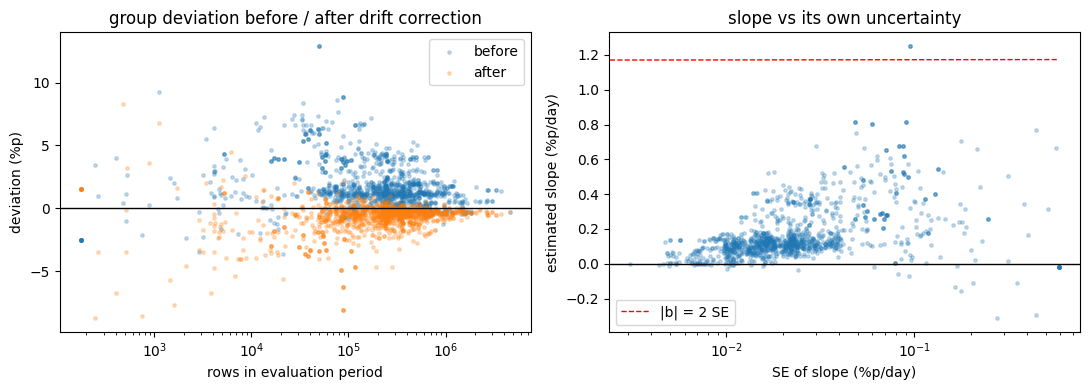

In [18]:
# ── 6-2) 작은 집단에서도 쓸 수 있나 — 조건 2개 조합으로 안정성을 봄 ─────
# 빔 서치는 조건을 3개까지 겹치므로 집단이 수백 명까지 내려감.
# 이 보정은 15일로 잰 선을 15일 앞까지 연장하는 구조라, 집단이 작으면
# 기울기 자체가 잡음이 되어 보정이 없던 편차를 만들어 낼 수 있음.
# 축 10개의 모든 쌍(45개)에서 칸을 만들어 크기별로 확인함
_t0 = time.time()


def _qbin(col, k=5):
    """경계는 설계대로 학습(정상) 기간 분위수에서 잡고 전체 행에 적용함"""
    x = mart[col].to_numpy().astype('float64')
    e = np.unique(np.nanquantile(x[is_train], np.linspace(0, 1, k + 1)))
    e[0], e[-1] = -np.inf, np.inf
    return pd.cut(x, e)


_axes = {'age'     : mart['age'],
         'city'    : mart['city'],
         'gender'  : mart['gender'],
         'channel' : mart['channel'],
         'dow'     : mart['base_dow'],
         'act_days': pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28]),
         'last'    : _qbin('days_since_last'),
         'weekend' : _qbin('weekend_ratio'),
         'signup'  : _qbin('days_since_signup'),
         'expire'  : _qbin('days_to_expire')}
_cd   = {k: _codes(v) for k, v in _axes.items()}
_keys = list(_cd)

_rows = []
for _i, _ka in enumerate(_keys):
    _ca, _la = _cd[_ka]
    for _kb in _keys[_i + 1:]:
        _cb, _lb = _cd[_kb]
        _cc = _ca * len(_lb) + _cb                     # 두 축을 곱해 칸 하나로 만듦
        _t  = drift(_cc[is_train], _cc[is_eval], len(_la) * len(_lb))
        _t['쌍'] = _ka + ' x ' + _kb
        _rows.append(_t[(_t['n학습'] >= 150) & (_t['n평가'] >= 150)])
_cells = pd.concat(_rows, ignore_index=True)
print('조건 2개 집단 {:,}개 (쌍 {}개에서, 학습·평가 각 150행 이상) — {:.0f}초'.format(
    len(_cells), len(_keys) * (len(_keys) - 1) // 2, time.time() - _t0))

# ── 축소(shrinkage) — 참 기울기의 분산 τ² 를 적률법으로 재서 b 를 0 쪽으로 당김 ──
# 작은 집단일수록 ±SE 가 커져 b 가 많이 깎임. 큰 집단은 거의 그대로 둠
_tau2 = max(_cells['기울기'].var() - (_cells['±SE'] ** 2).mean(), 0.0)
_cells['기울기축소'] = _cells['기울기'] * _tau2 / (_tau2 + _cells['±SE'] ** 2)
_cells['보정후축소']   = _cells['DID'] - _cells['기울기축소'] * _cells['_갭']
print('τ(참 기울기의 퍼짐) {:.3f}%p/일  — ±SE 가 이보다 크면 그 집단의 기울기는 대부분 잡음임'.format(
    np.sqrt(_tau2)))

# ── 크기별 — 보정이 흩어짐을 줄이는가, 어디서부터 해로워지는가 ───────────
_cells['크기'] = pd.cut(_cells['n평가'], [0, 1e3, 1e4, 1e5, 1e6, np.inf],
                        labels=['~1천', '1천~1만', '1만~10만', '10만~100만', '100만+'])
_g = _cells.groupby('크기', observed=True).apply(lambda d: pd.Series({
    '집단수'        : len(d),
    '±SE 중앙'      : d['±SE'].median(),
    '흩어짐 보정전' : d['평가'].std(),
    '흩어짐 DID'    : d['DID'].std(),
    '흩어짐 보정후'   : d['보정후'].std(),
    '흩어짐 보정후축소': d['보정후축소'].std(),
    '|보정후| 최대'   : d['보정후'].abs().max()}), include_groups=False)
print('\n집단 크기별 (흩어짐 = 집단 간 표준편차, %p):')
print(_g.to_string(formatters={'집단수': '{:,.0f}'.format}, float_format='{:.3f}'.format))
print('  → 보정전 > 보정후 면 보정이 일한 것이고, 보정전 < 보정후 면 잡음을 넣은 것임')
print('  → 축소가 작은 칸에서 보정후를 되돌려 놓으면 축소를 넣어야 한다는 뜻임')

# ── 그림 ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(_cells['n평가'], _cells['평가'], s=6, alpha=.25, label='before')
ax[0].scatter(_cells['n평가'], _cells['보정후'], s=6, alpha=.25, label='after')
ax[0].set_xscale('log'); ax[0].axhline(0, color='k', lw=1)
ax[0].set_xlabel('rows in evaluation period'); ax[0].set_ylabel('deviation (%p)')
ax[0].legend(); ax[0].set_title('group deviation before / after drift correction')
ax[1].scatter(_cells['±SE'], _cells['기울기'], s=6, alpha=.25)
ax[1].plot([0, _cells['±SE'].max()], [0, _cells['±SE'].max() * 2], 'r--', lw=1, label='|b| = 2 SE')
ax[1].set_xscale('log'); ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('SE of slope (%p/day)'); ax[1].set_ylabel('estimated slope (%p/day)')
ax[1].legend(); ax[1].set_title('slope vs its own uncertainty')
plt.tight_layout(); plt.show()

del _rows, _cd, _axes

### 6-1 에서 걸린 세 가지

| | 걸린 것 | 확인 |
|---|---|---|
| **A** | 보정후가 전부 조금씩 음수 | 3/30(데이터 경계 효과)이 주범인지 |
| **B** | 요일별 보정후가 들쭉날쭉 | ±SE 가 과소평가인지 |
| **C** | 외삽이 정말 되는지 모름 | 하락 없는 구간에서 미리 시험 |

**B** — 같은 날의 행은 함께 흔들리는데 지금까지 ±SE 는 행을 전부 독립으로 셌음.
날짜별 평균 편차를 점으로 보는 방식으로 바꿈(기울기·절편은 그대로, SE 만 달라짐).
합성 데이터 + 블록 부트스트랩 대조: 행 수준 **0.66배** / 날짜 수준 **0.90배**.
⚠️ 날짜가 2개뿐이면 직선이 두 점을 정확히 지나 SE 가 0 으로 찍힘 → `날짜수 < 3` 이면 ∞ 로 둠.

**C 플라시보** — P1 적합 3/1~7 → 검증 3/8~15(둘 다 정상 기간) / P2 현 설계 / P3 학습 7일 + ⑤.
P1 은 갭이 가장 짧아 가장 쉬운 조건임. 그런데도 안 되면 외삽 거리가 아니라 **적합 날짜 수**의 문제임.

In [19]:
# ── 6-3) A 3/30 제외 · B 날짜 묶음 표준오차 · C 플라시보 검증 ───────────
# 6-1 에서 셋이 걸렸음:
#   ① 보정후가 전부 조금씩 음수 → 3/30(데이터 경계 효과)이 주범인지 확인함
#   ② 요일별 보정후가 −1.39 ~ +0.06 으로 흔들림 → ±SE 가 거짓말을 하고 있어서임.
#      금요일은 학습 기간에 3/3·3/10 두 번뿐인데 행이 119만이라 ±SE 가 0.010 으로 찍힘.
#      같은 날의 행은 함께 흔들리므로 **날짜를 한 덩어리로 세는 표준오차**로 바꿔야 함
#   ③ 외삽이 정말 되는지 → 하락이 없는 구간을 잘라 미리 시험함(플라시보)

def fit_drift(code, K, m_tr, m_ev):
    """구간을 임의로 지정해 적합(m_tr) → 검증(m_ev) 함. code 는 전체 행 길이의 정수 코드임"""
    c, d_, v_ = code[m_tr], _dd[m_tr], _vv[m_tr]
    n   = np.bincount(c, minlength=K).astype('float64')
    Sd  = np.bincount(c, weights=d_,      minlength=K)
    Sv  = np.bincount(c, weights=v_,      minlength=K)
    Sdd = np.bincount(c, weights=d_ * d_, minlength=K)
    Sdv = np.bincount(c, weights=d_ * v_, minlength=K)
    Svv = np.bincount(c, weights=v_ * v_, minlength=K)
    with np.errstate(divide='ignore', invalid='ignore'):
        Sxx  = Sdd - Sd * Sd / n
        Syy  = Svv - Sv * Sv / n
        Sxy  = Sdv - Sd * Sv / n
        b    = Sxy / Sxx
        dbar = Sd / n
        mu   = Sv / n
        a    = mu - b * dbar
        SEr  = np.sqrt((Syy - b * Sxy) / (n - 2) / Sxx)      # 행 수준 (지금까지 쓰던 것)

    # ── 날짜 수준 표준오차 — 날짜별 평균 편차를 점으로 보고 선에서 벗어난 정도로 잼 ──
    # 같은 날의 행은 함께 흔들리므로(그날 전체에 걸리는 충격) 행을 따로 세면 안 됨.
    # 합성 데이터로 블록 부트스트랩과 대조해 참값의 0.90배로 확인함 (행 수준은 0.66배)
    days = np.unique(d_)
    di   = np.searchsorted(days, d_)
    gd   = c * len(days) + di
    ngd  = np.bincount(gd, minlength=K * len(days)).reshape(K, -1).astype('float64')
    vgd  = np.bincount(gd, weights=v_, minlength=K * len(days)).reshape(K, -1)
    with np.errstate(divide='ignore', invalid='ignore'):
        e   = np.nan_to_num(vgd / ngd - (a[:, None] + b[:, None] * days[None, :]))
        G   = (ngd > 0).sum(1)                                        # 학습에 쓴 날짜 수
        SEc = np.sqrt((ngd * e * e).sum(1) / np.maximum(G - 2, 1) / Sxx)
    # ⚠️ 날짜가 2개뿐이면 직선이 두 점을 정확히 지나 오차가 0 으로 찍힘 — 믿으면 안 됨
    SEc = np.where(G >= 3, SEc, np.inf)

    # ── 검증 구간 ────────────────────────────────────────────────────────
    ce, de, ve = code[m_ev], _dd[m_ev], _vv[m_ev]
    ne  = np.bincount(ce, minlength=K).astype('float64')
    Sde = np.bincount(ce, weights=de, minlength=K)
    Sve = np.bincount(ce, weights=ve, minlength=K)
    with np.errstate(divide='ignore', invalid='ignore'):
        mu_ev = Sve / ne
        gap   = Sde / ne - dbar
    return pd.DataFrame({'n학습': n, 'n평가': ne, '날짜수': G,
                         '기울기': b * 100, '±SE행': SEr * 100, '±SE날짜': SEc * 100,
                         '학습': mu * 100, '평가': mu_ev * 100,
                         '보정후': (mu_ev - mu - b * gap) * 100,
                         '±보정': np.abs(gap) * SEc * 100, '갭': gap})


_habit = pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28],
                labels=['0 (미측정)', '1-3일', '4-10일', '11-20일', '21-28일'])
_dow   = mart['base_dow'].map({0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'})
_z     = np.zeros(len(mart), dtype='int32')
_m28   = is_eval & (_dd <= 28)                      # 3/30 을 뺀 평가 구간

# ══ A) 3/30 을 빼면 '전부 음수' 가 사라지는가 ═══════════════════════════
print('═' * 72)
print('A) 3/30 제외 — 데이터 경계 효과(결과일 3/31 의 DAU 가 −3.9%)가 주범인지')
for _key, _lab in [(_habit, '습관 — 2월 활동일 수'), (_dow, '기준일 요일')]:
    _c, _l = _codes(_key)
    _p1 = fit_drift(_c, len(_l), is_train, is_eval)
    _p2 = fit_drift(_c, len(_l), is_train, _m28)
    _t  = pd.DataFrame({'n학습': _p1['n학습'], '기울기': _p1['기울기'],
                        '평가(포함)': _p1['평가'], '보정후(포함)': _p1['보정후'],
                        '평가(제외)': _p2['평가'], '보정후(제외)': _p2['보정후']})
    _t.index = _l
    _t = _t[_t['n학습'] > 0]
    print('\n[{}]'.format(_lab))
    print(_t.to_string(formatters={'n학습': '{:,.0f}'.format}, float_format='{:+.3f}'.format))
_a1 = fit_drift(_z, 1, is_train, is_eval).iloc[0]
_a2 = fit_drift(_z, 1, is_train, _m28).iloc[0]
print('\n[전체]  3/30 포함  평가 {:+.3f} → 보정후 {:+.3f}   |   3/30 제외  평가 {:+.3f} → 보정후 {:+.3f}'.format(
    _a1['평가'], _a1['보정후'], _a2['평가'], _a2['보정후']))

# ══ B) 표준오차 — 행 수준은 날짜가 적은 집단에서 거짓말을 함 ════════════
print('\n' + '═' * 72)
print('B) 표준오차: 행 수준 vs 날짜 묶음  (날짜수 = 학습 기간에 그 집단이 나타난 날 수)')
for _key, _lab in [(_dow, '기준일 요일  ★ 날짜가 2~3개뿐인 집단'), (_habit, '습관 — 2월 활동일 수')]:
    _c, _l = _codes(_key)
    _t = fit_drift(_c, len(_l), is_train, _m28)
    _t.index = _l
    _t = _t[_t['n학습'] > 0]
    _t['배수'] = _t['±SE날짜'] / _t['±SE행']
    _t['|기울기|/SE날짜'] = _t['기울기'].abs() / _t['±SE날짜']
    print('\n[{}]'.format(_lab))
    print(_t[['n학습', '날짜수', '기울기', '±SE행', '±SE날짜', '배수',
              '|기울기|/SE날짜', '±보정', '보정후']]
          .to_string(formatters={'n학습': '{:,.0f}'.format, '날짜수': '{:.0f}'.format},
                     float_format='{:+.3f}'.format))
print('\n  → 배수가 크면 지금까지의 ±SE 가 그만큼 과소평가였던 것임')
print('  → |기울기|/SE날짜 가 2 미만이면 그 집단의 기울기는 0 과 구분되지 않음 → 보정하면 안 됨')
print('  → ±보정 = 그 집단에 실제로 더하거나 빼는 양의 불확실성 (|갭| x SE날짜)')

# ══ C) 플라시보 — 하락이 없는 구간을 잘라 외삽이 되는지 미리 시험함 ═════
print('\n' + '═' * 72)
print('C) 플라시보 — 적합 구간과 검증 구간을 바꿔 가며 보정후가 0 에 머무는지')
_설정 = [('P1  적합 3/1~3/7  → 검증 3/8~3/15',  _dd <= 6,                (_dd >= 7) & (_dd <= 14)),
         ('P2  적합 3/1~3/15 → 검증 3/16~3/29', is_train,                _m28),
         ('P3  적합 3/9~3/15 → 검증 3/16~3/29', (_dd >= 8) & (_dd <= 14), _m28)]
_c, _l = _codes(_habit)
_res, _tot = {}, {}
for _nm, _mt, _me in _설정:
    _t = fit_drift(_c, len(_l), _mt, _me)
    _t.index = _l
    _res[_nm] = _t[_t['n학습'] > 0]['보정후']
    _tot[_nm] = fit_drift(_z, 1, _mt, _me).iloc[0]
_tab = pd.DataFrame(_res)
_tab.loc['── 전체 ──'] = [_tot[k]['보정후'] for k in _tab.columns]
_tab.loc['(갭, 일)']   = [_tot[k]['갭']   for k in _tab.columns]
print('\n집단별 보정후(%p) — 0 에 가까울수록 외삽이 된 것임:')
print(_tab.to_string(float_format='{:+.3f}'.format))
print('\n  P1 은 둘 다 정상 기간이라 하락이 없는 것이 확실함 → 여기서 0 이 아니면 방법 자체가 안 되는 것임')
print('  P3 은 ② 안(학습 7일)과 ⑤ 를 합친 것임 — 갭은 짧아지지만 적합에 쓰는 날짜가 7개로 줄어듦')

════════════════════════════════════════════════════════════════════════
A) 3/30 제외 — 데이터 경계 효과(결과일 3/31 의 DAU 가 −3.9%)가 주범인지

[습관 — 2월 활동일 수]
              n학습    기울기  평가(포함)  보정후(포함)  평가(제외)  보정후(제외)
0 (미측정)   243,810 +0.353  +3.956  -1.089  +3.979  -0.874
1-3일      231,898 +0.446  +6.693  -0.267  +6.763  +0.027
4-10일     916,107 +0.354  +4.174  -1.161  +4.307  -0.851
11-20일  2,622,029 +0.169  +1.948  -0.619  +2.204  -0.276
21-28일  4,789,140 +0.005  -0.295  -0.313  -0.058  -0.074

[기준일 요일]
        n학습    기울기  평가(포함)  보정후(포함)  평가(제외)  보정후(제외)
금 1,188,509 +0.133  +0.704  -1.136  +0.704  -1.136
목 1,165,542 +0.101  +0.351  -1.388  +1.407  +0.022
수 1,749,883 +0.112  +2.006  +0.063  +2.006  +0.063
월 1,165,778 +0.128  +1.762  +0.007  +1.762  +0.007
일 1,187,945 +0.137  +1.842  -0.031  +1.842  -0.031
토 1,176,621 +0.146  +0.827  -1.272  +0.827  -1.272
화 1,168,706 +0.149  +1.692  -0.451  +1.692  -0.451

[전체]  3/30 포함  평가 +1.247 → 보정후 -0.397   |   3/30 제외  평가 +1.462 → 보정후 -0.126

═══════════════

### 가설 검증 — 표류가 '혼합' 때문인가 (10/8)

> 가벼운 집단은 '꾸준한 라이트 유저' 와 '곧 이탈할 신규' 가 **섞인 것**이고,
> 그 혼합을 가르면 **날짜 정보 없이** 표류가 사라진다

두 축으로 쪼개 봄 — **가입 시기**(가설의 직접 검증)와 **`days_since_last`**(이미 모델에 있는 변수).

⚠️ 가입일은 **분석 축으로만** 씀. `기준일 = 가입 후 경과일 + 가입일` 이라 모델에 넣으면
달력 날짜가 복원됨 (④′ 기각 사유와 같은 구조).

**읽는 법** — 칸 기울기의 **가중평균**을 쪼개기 전과 비교함. 0 근처로 가면 그 축이 혼합의 정체이고,
그대로 남으면 **같은 칸 안에서도 선택이 일어나는 것임.** 비중도 함께 볼 것.

In [20]:
# ── 6-4) 가설 검증 — 가벼운 집단의 표류가 '혼합' 때문인가 ───────────────
# 가설(10/8 사용자 제안): "2월에 1~3일만 들은 사람" 은 ① 꾸준한 라이트 유저 와
#   ② 2월에 처음 와서 곧 이탈할 사람 이 섞인 것이고, 그 혼합이 표류를 만든다.
#   혼합을 가르는 변수를 찾으면 날짜 정보 없이 표류가 사라진다.
# 보는 법: 쪼갠 뒤에도 칸마다 기울기가 남으면 그 축은 혼합의 정체가 아님.
#          칸 기울기가 0 근처로 가면 그 축이 정답임.
# ⚠️ 가입일은 **분석 축으로만** 씀 — 기대 모델에 넣으면 기준일 = 경과일 + 가입일 이라
#    달력 날짜가 복원됨 (④' 기각 사유와 같은 구조)

_hb = pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28],
             labels=['0 (미측정)', '1-3일', '4-10일', '11-20일', '21-28일'])
_c_h, _l_h = _codes(_hb)
_base = fit_drift(_c_h, len(_l_h), is_train, _m28)      # 쪼개기 전 기울기 (대조값)
_base.index = _l_h


def cross(key2, lab2, 볼집단):
    """습관 집단 x 다른 축으로 쪼개 칸마다 기울기를 봄"""
    c2, l2 = _codes(key2)
    K2 = len(l2)
    t = fit_drift(_c_h * K2 + c2, len(_l_h) * K2, is_train, _m28)
    t.index = pd.MultiIndex.from_product([_l_h, l2])
    print('\n' + '━' * 78)
    print('습관 x {}'.format(lab2))
    for h in 볼집단:
        s = t.loc[h].copy()
        s = s[s['n학습'] >= 500]
        if len(s) == 0:
            continue
        s['비중'] = s['n평가'] / s['n평가'].sum()
        w = s['비중'] / s['비중'].sum()
        print('\n[{}]   쪼개기 전 기울기 {:+.3f}%p/일   평가 {:+.3f}   보정후 {:+.3f}'.format(
            h, _base.loc[h, '기울기'], _base.loc[h, '평가'], _base.loc[h, '보정후']))
        print(s[['n평가', '비중', '기울기', '±SE날짜', '평가', '보정후']].to_string(
            formatters={'n평가': '{:,.0f}'.format}, float_format='{:+.3f}'.format))
        print('   → 칸 기울기의 가중평균 {:+.3f}%p/일  (쪼개기 전 {:+.3f} 에서 {:.0f}% 남음)'.format(
            (w * s['기울기']).sum(), _base.loc[h, '기울기'],
            abs((w * s['기울기']).sum() / _base.loc[h, '기울기']) * 100))


# ══ ① 가입 시기로 쪼갬 — 선생님 가설의 직접 검증 ═══════════════════════
# 가입일(달력) = 기준일 − 가입 후 경과일.  단위는 '3/1 로부터 며칠' 임
_signup = mart['day'].to_numpy().astype('float64') - mart['days_since_signup'].to_numpy()
_sb = pd.cut(_signup, [-np.inf, -365, -60, -29, -1, np.inf],
             labels=['1년+ 전', '작년~1월 전', '1월 가입', '2월 가입', '3월 가입'])
cross(_sb, '가입 시기  ★ 가설의 직접 검증', ['1-3일', '4-10일', '0 (미측정)', '21-28일'])

# ══ ② 2월 안에서 언제 들었나 — 이미 모델에 있는 변수로도 갈리나 ════════
# days_since_last = 2/28 에서 마지막 활동일까지의 일수 (0 = 2/28 에도 들음)
_dl = pd.cut(mart['days_since_last'], [-1, 0, 2, 6, 13, 27],
             labels=['0일(2/28까지)', '1-2일', '3-6일', '7-13일', '14일+'])
cross(_dl, '2월 마지막 활동 이후 일수 (days_since_last, 이미 모델에 있음)',
      ['1-3일', '4-10일'])

print('\n' + '━' * 78)
print('읽는 법')
print('  · 칸 기울기가 전부 0 근처  → 그 축이 혼합의 정체임. 변수로 넣으면 표류가 사라짐')
print('  · 칸 기울기가 그대로 남음  → 그 축은 아님. 같은 칸 안에서도 선택이 일어나는 것임')
print('  · 비중도 함께 볼 것 — 어느 한 칸이 압도적이면 "쪼갰다" 고 할 수 없음')


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
습관 x 가입 시기  ★ 가설의 직접 검증

[1-3일]   쪼개기 전 기울기 +0.446%p/일   평가 +6.763   보정후 +0.027
            n평가     비중    기울기  ±SE날짜     평가     보정후
1년+ 전   164,003 +0.682 +0.499 +0.065 +6.369 -0.842
작년~1월 전  39,720 +0.165 +0.518 +0.072 +6.513 -0.684
1월 가입     4,660 +0.019 +0.624 +0.111 +7.175 -3.933
2월 가입    31,968 +0.133 +0.315 +0.062 +9.031 +3.154
   → 칸 기울기의 가중평균 +0.480%p/일  (쪼개기 전 +0.446 에서 108% 남음)

[4-10일]   쪼개기 전 기울기 +0.354%p/일   평가 +4.307   보정후 -0.851
            n평가     비중    기울기  ±SE날짜     평가     보정후
1년+ 전   689,175 +0.758 +0.353 +0.049 +4.250 -0.854
작년~1월 전 151,406 +0.167 +0.366 +0.050 +4.204 -1.250
1월 가입    17,036 +0.019 +0.361 +0.084 +4.568 -0.471
2월 가입    51,378 +0.057 +0.337 +0.048 +5.288 +0.200
   → 칸 기울기의 가중평균 +0.354%p/일  (쪼개기 전 +0.354 에서 100% 남음)

[0 (미측정)]   쪼개기 전 기울기 +0.353%p/일   평가 +3.979   보정후 -0.874
            n평가     비중    기울기  ±SE날짜     평가     보정후
1년+ 전   156,596 +0.397 +0.635 +0.089 +6.125 -2.729

### 게이트 vs 축소 — 작은 집단을 무엇으로 지키나

6-2 에서 1만 행 미만은 보정이 오히려 해로웠음. 6-3 에서 ±SE 를 날짜 수준으로 고쳤으므로 다시 봄.

| | 방식 |
|---|---|
| **게이트** | `날짜수 < 3` 또는 `\|기울기\|/SE < 2` → **b = 0** (칼로 자름) |
| **축소** | `τ²/(τ²+SE²)` 만큼 0 쪽으로 당김 (믿는 만큼만, 연속적) |

τ 는 **참 기울기의 퍼짐**임. 측정한 b 의 분산이 `진짜 퍼짐 + 측정 오차` 로 나뉘는 성질을 써서
`τ² = var(b) − mean(SE²)` 로 구함. SE 가 τ 보다 크면 그 집단의 기울기는 **대부분 잡음**임.

보는 값 둘 — **집단 간 흩어짐**(기준선이 고른가)과 **|보정후| 상위 1%**(가짜 경보가 될 극단값).

In [21]:
# ── 6-5) 작은 집단을 무엇으로 지키나 — 게이트 vs 축소 ───────────────────
# 6-2 에서 1만 행 미만은 보정이 오히려 해로웠음(흩어짐 2.31 → 4.43).
# 원인은 기울기 추정의 잡음인데, 6-3 에서 ±SE 를 날짜 수준으로 고쳤으므로 다시 봄.
# 다섯 가지를 같은 집단에 적용해 크기별로 비교함.
#   보정없음 / DID(수준만) / 그대로 / 게이트 / 축소 / 게이트+축소
# 게이트:  날짜수 < 3 이거나 |기울기|/SE날짜 < 2 이면 b = 0 (아예 보정 안 함)
# 축소  :  b 를 τ²/(τ²+SE²) 만큼 0 쪽으로 당김 (못 믿을수록 많이 깎임)
_t0 = time.time()


def _qbin(col, k=5):
    """경계는 설계대로 학습(정상) 기간 분위수에서 잡음"""
    x = mart[col].to_numpy().astype('float64')
    e = np.unique(np.nanquantile(x[is_train], np.linspace(0, 1, k + 1)))
    e[0], e[-1] = -np.inf, np.inf
    return pd.cut(x, e)


_axes = {'age'     : mart['age'],          'city'    : mart['city'],
         'gender'  : mart['gender'],       'channel' : mart['channel'],
         'dow'     : mart['base_dow'],     'act_days': pd.cut(mart['act_days'], [-1, 0, 3, 10, 20, 28]),
         'last'    : _qbin('days_since_last'),   'weekend': _qbin('weekend_ratio'),
         'signup'  : _qbin('days_since_signup'), 'expire' : _qbin('days_to_expire')}
_cd   = {k: _codes(v) for k, v in _axes.items()}
_keys = list(_cd)

_rows = []
for _i, _ka in enumerate(_keys):
    _ca, _la = _cd[_ka]
    for _kb in _keys[_i + 1:]:
        _cb, _lb = _cd[_kb]
        _t = fit_drift(_ca * len(_lb) + _cb, len(_la) * len(_lb), is_train, _m28)
        _t['쌍'] = _ka + ' x ' + _kb
        _rows.append(_t[(_t['n학습'] >= 150) & (_t['n평가'] >= 150)])
_g = pd.concat(_rows, ignore_index=True)
_g = _g[np.isfinite(_g['기울기'])].copy()          # 날짜가 1개뿐이면 기울기가 정의 안 됨
print('조건 2개 집단 {:,}개 (쌍 {}개, 평가는 3/30 제외) — {:.0f}초'.format(
    len(_g), len(_keys) * (len(_keys) - 1) // 2, time.time() - _t0))

# ── 네 가지 기울기를 만듦 ───────────────────────────────────────────────
_tval  = _g['기울기'].abs() / _g['±SE날짜']                 # |t| (SE 가 inf 면 0 이 됨)
_pass  = (_g['날짜수'] >= 3) & (_tval >= 2)                 # 게이트 통과
_fin   = np.isfinite(_g['±SE날짜'])
_tau2  = max(_g.loc[_fin, '기울기'].var() - (_g.loc[_fin, '±SE날짜'] ** 2).mean(), 0.0)
_wt    = (_tau2 / (_tau2 + _g['±SE날짜'] ** 2)).fillna(0.0)  # inf → 0
print('τ(참 기울기의 퍼짐) {:.3f}%p/일   축소 비율 중앙값 {:.2f}   게이트 통과 {:.1%}'.format(
    np.sqrt(_tau2), _wt.median(), _pass.mean()))

_방식 = {'보정없음'    : None,
        'DID(수준만)' : 0.0,
        '그대로'      : _g['기울기'],
        '게이트'      : _g['기울기'].where(_pass, 0.0),
        '축소'        : _g['기울기'] * _wt,
        '게이트+축소' : (_g['기울기'] * _wt).where(_pass, 0.0)}
for _nm, _b in _방식.items():
    _g[_nm] = _g['평가'] if _b is None else _g['평가'] - _g['학습'] - _b * _g['갭']

# ── 크기별 흩어짐 ───────────────────────────────────────────────────────
_g['크기'] = pd.cut(_g['n평가'], [0, 1e3, 1e4, 1e5, 1e6, np.inf],
                    labels=['~1천', '1천~1만', '1만~10만', '10만~100만', '100만+'])
_sd = _g.groupby('크기', observed=True).apply(
    lambda d: pd.Series({**{'집단수': len(d), '게이트통과': _pass[d.index].mean()},
                         **{k: d[k].std() for k in _방식}}), include_groups=False)
print('\n집단 간 흩어짐 (%p, 작을수록 좋음):')
print(_sd.to_string(formatters={'집단수': '{:,.0f}'.format, '게이트통과': '{:.0%}'.format},
                    float_format='{:.3f}'.format))
_best = _sd[list(_방식)].idxmin(axis=1)
print('\n크기별 최선:')
for _k, _v in _best.items():
    print('  {:<12s} {:<12s} ({:.3f} vs 보정없음 {:.3f})'.format(
        str(_k), _v, _sd.loc[_k, _v], _sd.loc[_k, '보정없음']))

# ── 꼬리 — 가짜 경보가 될 만한 극단값이 줄었나 ──────────────────────────
print('\n|보정후| 상위 1% 분위 (%p) — 작을수록 가짜 경보가 적음:')
_q = _g.groupby('크기', observed=True).apply(
    lambda d: pd.Series({k: d[k].abs().quantile(0.99) for k in _방식}), include_groups=False)
print(_q.to_string(float_format='{:.3f}'.format))

print('\n읽는 법')
print('  · 보정없음보다 작아야 그 방식이 일한 것임')
print('  · 게이트 통과율이 낮은 크기대에서 "게이트" 가 "그대로" 보다 나으면 게이트가 필요한 것임')
print('  · 큰 집단에서 셋이 비슷하면, 게이트는 작은 집단 보험일 뿐 큰 집단엔 무해하다는 뜻임')

조건 2개 집단 1,181개 (쌍 45개, 평가는 3/30 제외) — 56초
τ(참 기울기의 퍼짐) 0.146%p/일   축소 비율 중앙값 0.94   게이트 통과 65.5%

집단 간 흩어짐 (%p, 작을수록 좋음):
         집단수 게이트통과  보정없음  DID(수준만)   그대로   게이트    축소  게이트+축소
크기                                                          
~1천       18    6% 2.704     1.605 4.183 2.895 1.580   1.693
1천~1만     46   26% 2.347     2.497 2.793 3.421 2.500   2.746
1만~10만   283   71% 2.486     2.446 1.485 2.165 1.727   1.710
10만~100만 774   67% 1.272     1.234 0.656 1.041 0.923   0.922
100만+     60   75% 0.727     0.703 0.192 0.218 0.185   0.210

크기별 최선:
  ~1천          축소           (1.580 vs 보정없음 2.704)
  1천~1만        보정없음         (2.347 vs 보정없음 2.347)
  1만~10만       그대로          (1.485 vs 보정없음 2.486)
  10만~100만     그대로          (0.656 vs 보정없음 1.272)
  100만+        축소           (0.185 vs 보정없음 0.727)

|보정후| 상위 1% 분위 (%p) — 작을수록 가짜 경보가 적음:
          보정없음  DID(수준만)   그대로   게이트    축소  게이트+축소
크기                                                
~1천      4.575     5.301 8.785 8.323 4.318   5.301

### 6절 판정 — ⑤ 채택. 조건은 셋

| | |
|---|---|
| **방법** | 집단마다 학습 기간에서 기준선을 재서 뺌 (**빔 서치 점수 함수 안에서**) |
| **조건 ①** | **정상 기간 15일 필수** — 7일이면 기울기를 절반으로 과소추정함 |
| **조건 ②** | **평가 행 1만 이상인 집단만** 보정. 그 아래는 전체 기준선을 뺌 |
| **조건 ③** | 요일·공휴일처럼 날짜와 얽힌 축은 날짜수 부족으로 **자동 제외** |

게이트·축소는 **쓰지 않음** — 6-5 에서 둘 다 단순 임계값보다 나빴음.

#### 1) 보정이 일하는가 — ⭕ (3/30 제외 기준)

| 습관 집단 | 비중 | 기울기 | 평가 | **보정후** | *(참고) ④′* |
|---|---|---|---|---|---|
| 0 (미측정) | 4.4% | +0.353 | +3.979 | **−0.874** | +0.010 |
| 1~3일 | 2.7% | +0.446 | +6.763 | **+0.027** | −2.728 |
| 4~10일 | 10.1% | +0.354 | +4.307 | **−0.851** | −4.379 |
| 11~20일 | 27.5% | +0.169 | +2.204 | **−0.276** | −2.827 |
| **21~28일 (헤비)** | 48.9% | **+0.005** | −0.058 | **−0.074** | **−1.410** |
| 전체 | 100% | +0.110 | +1.462 | **−0.126** | — |

흩어짐 0.708 → **0.277**(−61%), 최대 절댓값 6.693 → 2.467.
**④′ 와의 결정적 차이는 헤비 집단** — 기울기가 0 이라 손대지 않음(④′ 는 5배 악화시켜 기각됐음).
남은 음수(미측정 −0.874, 4~10일 −0.851)는 보정 불확실성 ±0.805 · ±0.650 안쪽임.

#### 2) 크기 하한 = 1만 행 (6-5, 조건 2개 집단 1,181개)

| 평가 행 | 보정없음 | 그대로 | 게이트 | 축소 |
|---|---|---|---|---|
| ~1천 | 2.704 | 4.183 | 2.895 | **1.580** |
| 1천~1만 | **2.347** | 2.793 | 3.421 | 2.500 |
| 1만~10만 | 2.486 | **1.485** | 2.165 | 1.727 |
| 10만~100만 | 1.272 | **0.656** | 1.041 | 0.923 |
| 100만+ | 0.727 | 0.192 | 0.218 | **0.185** |

- **게이트 기각** — 모든 크기대에서 "그대로" 보다 나쁨. 불확실한 기울기는 **어차피 작아 보정량도 0 에 가까운데**, 게이트는 가끔 진짜 큰 기울기까지 0 으로 만들어 손해를 봄
- **축소 기각** — 1만~10만 에서 `w ≒ 0.5` 가 되어 **진짜 기울기를 절반으로 깎아 과소보정**함.
  τ 를 전체에서 하나로 구한 탓임
- → **1만 행 임계값 하나로 충분함** (≒ 유저 700명). 전체 후보의 22.9% 는 날짜수 3 미만이라 자동 제외됨

#### 3) 혼합 가설 — 기각 (6-4)

| 쪼갠 축 | 집단 | 쪼개기 전 | 칸 가중평균 | 남은 비율 |
|---|---|---|---|---|
| 가입 시기 | 1~3일 | +0.446 | +0.480 | **108%** |
| 가입 시기 | 4~10일 | +0.354 | +0.354 | **100%** |
| `days_since_last` | 1~3일 | +0.446 | +0.517 | **116%** |

> 표류는 **구성이 변해서가 아니라 같은 사람들 안에서 걸러져서** 생김.
> 선택은 "그날 들었는가" 로 일어나는데 이는 **유저 × 날짜 단위 사건**이라,
> 2월 스냅샷을 아무리 잘게 나눠도 누가 3월 말까지 남을지 알 수 없음.

**부수 발견** — 1~3일 집단은 2월 신규가 아니라 **68.2% 가 1년 이상 된 기존 유저**이고,
기울기도 1년+ 가입 **+0.499** > 2월 가입 **+0.315** 로 방향이 반대임.
"신규라 곧 이탈" 이 아니라 **"오래 썼는데 2월에 식은 장기 유저"** 임.

#### 4) 세 갈래 논증 — 계획서에 쓸 값이 있음

| 길 | 결과 |
|---|---|
| **A** 모델 **안에** 변수를 넣어 없앤다 (④′) | ❌ 달력을 외우고 외삽 불가 → 과보정 |
| **B** 집단을 쪼개 **혼합**을 가른다 | ❌ 쪼개도 100~116% 남음 |
| **C** **기준선을 재서 뺀다** (⑤) | ⭕ 전체 보정후 −0.126%p, 흩어짐 −61% |

A·B 가 막히는 것을 수치로 보였기 때문에 **C 가 정당해짐.**

#### 5) 구현 4번(빔 서치)에 넘길 것

- 보정은 **점수 함수 안에** 들어가야 함. 사후 적용은 안 됨 — 1단계에서 잘린 조건은 조합으로도 못 올라옴
- 빔 서치가 **정상 기간 행까지** 들고 있어야 함 (평가 902만 → 정상+평가 1,781만)
- 집단마다 합 7개: 평가 `n · Σdev` + 정상 `n · Σd · Σdev · Σd² · Σd·dev`
- ② 안(학습 7일)과 ⑤ 는 상충함(갭을 줄이는 대신 날짜 수가 모자라짐) → **15일을 택함**
- 현업 적용 시 **롤링 재학습**이 전제임 — 습관 창이 과거에 고정되면 생존 선택이 계속 쌓임
- ⚠️ **한계**: 1만 행 미만 가벼운 집단의 진짜 하락은 **놓칠 수 있음**(거짓 음성).
  주입 실험에서 정답 집단 크기를 바꿔 가며 곡선으로 보일 것